In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/aptos2019-blindness-detection/sample_submission.csv
/kaggle/input/competitions/aptos2019-blindness-detection/train.csv
/kaggle/input/competitions/aptos2019-blindness-detection/test.csv
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/ef476be214d4.png
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/6dcde47060f9.png
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/ec363f48867b.png
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/17f6c7072f61.png
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/b49b2fac2514.png
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/af6166d57f13.png
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/8d13c46e7d75.png
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/c3b15bf9b4bc.png
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/be68322c7223.png
/kagg

In [1]:
import pandas as pd

dataset_path = "/kaggle/input/competitions/aptos2019-blindness-detection"

train_csv = dataset_path + "/train.csv"

df = pd.read_csv(train_csv)

print("Shape:", df.shape)

df.head()

Shape: (3662, 2)


,id_code,diagnosis
0,000c1434d8d7,2
1,001639a390f0,4
2,0024cdab0c1e,1
3,002c21358ce6,0
4,005b95c28852,0


In [2]:
# Count images in each DR class
class_counts = df['diagnosis'].value_counts().sort_index()

print("Number of images in each class:")
print(class_counts)

Number of images in each class:
diagnosis
0    1805
1     370
2     999
3     193
4     295
Name: count, dtype: int64


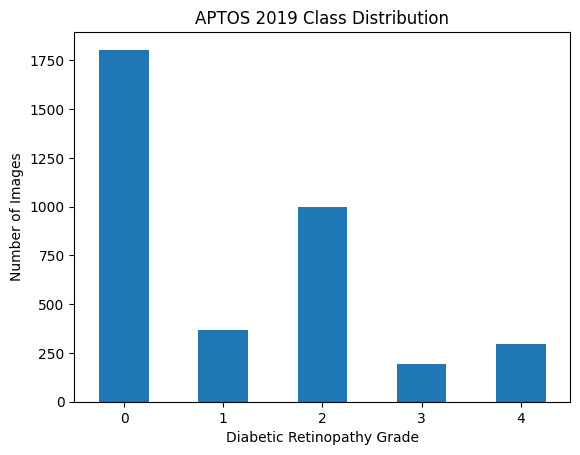

In [3]:
import matplotlib.pyplot as plt

class_counts.plot(kind='bar')

plt.xlabel("Diabetic Retinopathy Grade")
plt.ylabel("Number of Images")
plt.title("APTOS 2019 Class Distribution")
plt.xticks(rotation=0)
plt.show()

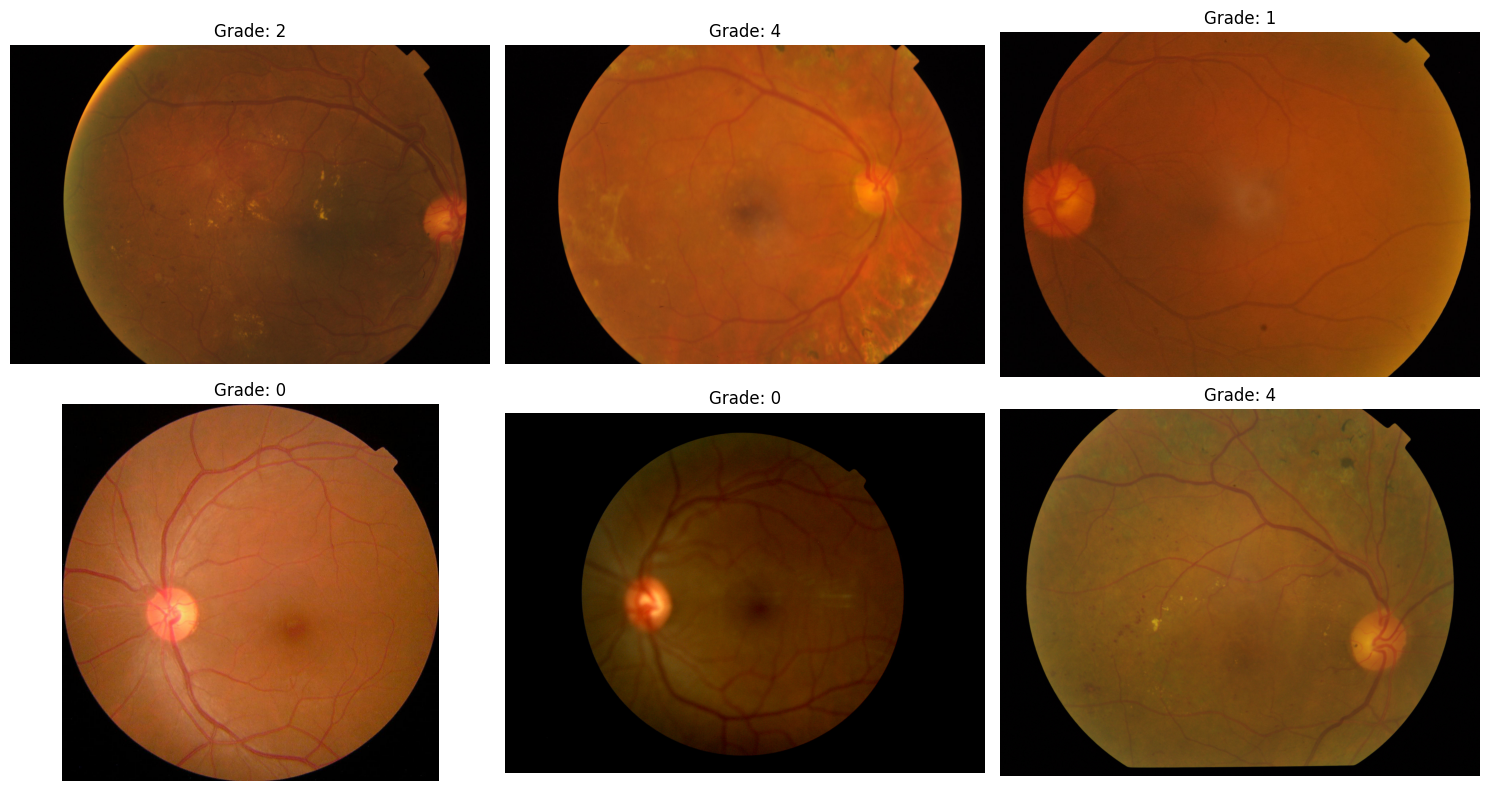

In [4]:
import matplotlib.pyplot as plt
from PIL import Image
import os

image_dir = dataset_path + "/train_images"

# Take the first 6 image IDs
sample_ids = df['id_code'].head(6)

plt.figure(figsize=(15, 8))

for i, image_id in enumerate(sample_ids):
    image_path = os.path.join(image_dir, image_id + ".png")
    
    image = Image.open(image_path)
    
    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title(f"Grade: {df.iloc[i]['diagnosis']}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [5]:
image_sizes = []

for image_id in df['id_code'].head(100):
    image_path = os.path.join(image_dir, image_id + ".png")
    image = Image.open(image_path)
    image_sizes.append(image.size)

print("First 10 image sizes:")
print(image_sizes[:10])

First 10 image sizes:
[(3216, 2136), (3216, 2136), (2416, 1736), (1050, 1050), (2048, 1536), (3388, 2588), (2588, 1958), (3216, 2136), (2588, 1958), (2416, 1736)]


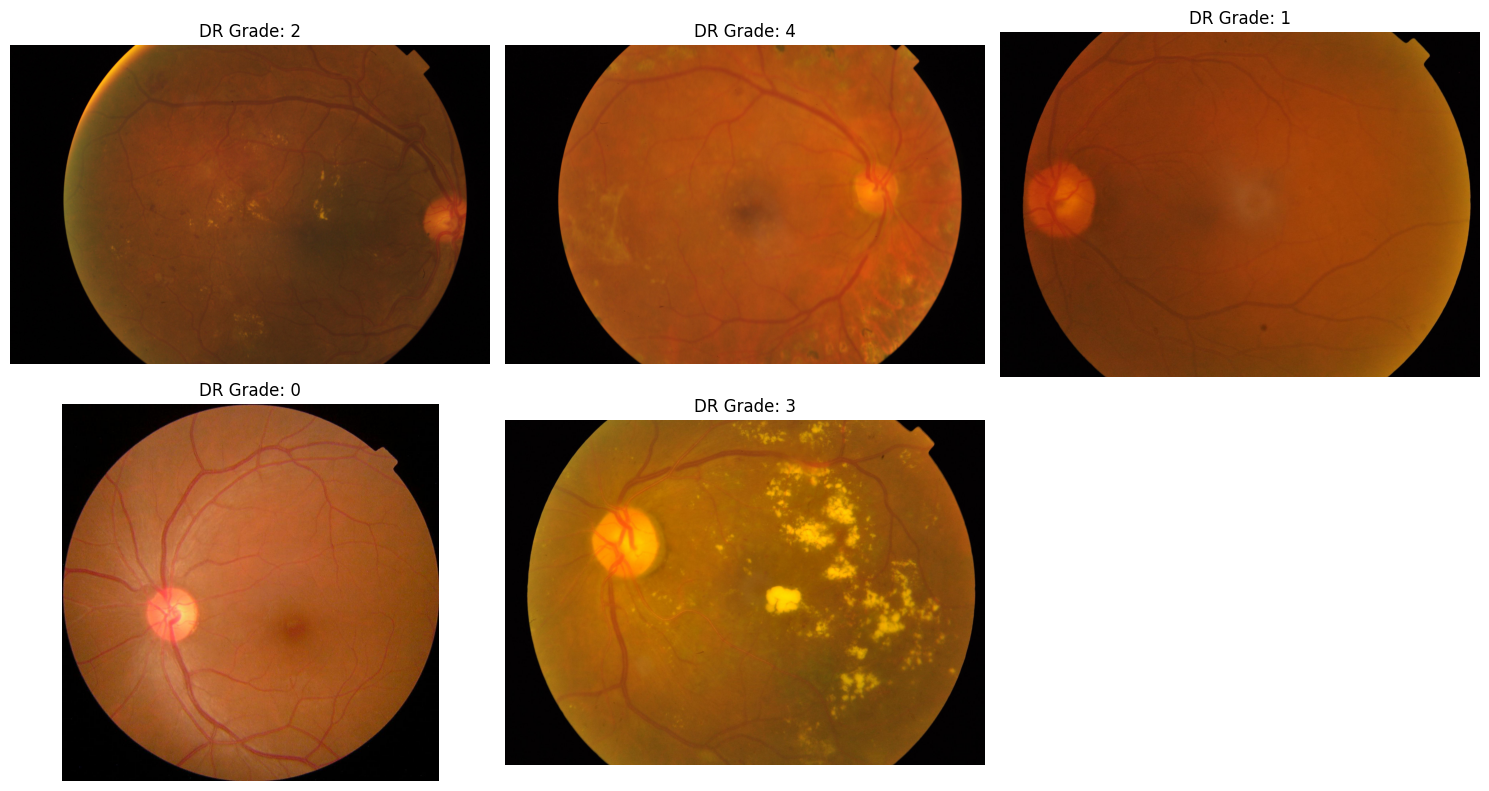

In [6]:
import matplotlib.pyplot as plt
from PIL import Image
import os

# Select 6 images from different DR grades
sample_df = df.groupby('diagnosis').head(1)

plt.figure(figsize=(15, 8))

for i, (_, row) in enumerate(sample_df.iterrows()):
    image_path = os.path.join(image_dir, row['id_code'] + ".png")
    image = Image.open(image_path)

    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title(f"DR Grade: {row['diagnosis']}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
# Check the important columns
print(df.columns)

# Show first 5 rows
display(df.head())

# Check whether every image exists
missing_images = []

for image_id in df['id_code']:
    image_path = os.path.join(image_dir, image_id + ".png")
    if not os.path.exists(image_path):
        missing_images.append(image_id)

print("Total images:", len(df))
print("Missing images:", len(missing_images))

Index(['id_code', 'diagnosis'], dtype='object')


,id_code,diagnosis
0,000c1434d8d7,2
1,001639a390f0,4
2,0024cdab0c1e,1
3,002c21358ce6,0
4,005b95c28852,0


Total images: 3662
Missing images: 0


In [9]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import os

In [10]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [11]:
# Test our preprocessing on one real APTOS image

image_id = df.iloc[0]['id_code']

image_path = os.path.join(
    image_dir,
    image_id + ".png"
)

image = Image.open(image_path).convert("RGB")

print("Image ID:", image_id)
print("Original size:", image.size)

processed_image = transform(image)

print("Processed shape:", processed_image.shape)
print("Diagnosis:", df.iloc[0]['diagnosis'])

Image ID: 000c1434d8d7
Original size: (3216, 2136)
Processed shape: torch.Size([3, 224, 224])
Diagnosis: 2


In [12]:
from sklearn.model_selection import train_test_split

# 80% training, 20% validation
train_df, val_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df['diagnosis'],
    random_state=42
)

print("Total images:", len(df))
print("Training images:", len(train_df))
print("Validation images:", len(val_df))

print("\nTraining class distribution:")
print(train_df['diagnosis'].value_counts().sort_index())

print("\nValidation class distribution:")
print(val_df['diagnosis'].value_counts().sort_index())

Total images: 3662
Training images: 2929
Validation images: 733

Training class distribution:
diagnosis
0    1444
1     296
2     799
3     154
4     236
Name: count, dtype: int64

Validation class distribution:
diagnosis
0    361
1     74
2    200
3     39
4     59
Name: count, dtype: int64


In [13]:
class DRDataset(Dataset):
    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        image_id = self.dataframe.loc[idx, 'id_code']
        label = self.dataframe.loc[idx, 'diagnosis']

        image_path = os.path.join(
            self.image_dir,
            image_id + ".png"
        )

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)

In [14]:
train_dataset = DRDataset(
    dataframe=train_df,
    image_dir=image_dir,
    transform=transform
)

val_dataset = DRDataset(
    dataframe=val_df,
    image_dir=image_dir,
    transform=transform
)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))

Training dataset: 2929
Validation dataset: 733


In [15]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 92
Validation batches: 23


In [16]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("First 10 labels:", labels[:10])

Images shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
First 10 labels: tensor([0, 2, 0, 0, 2, 2, 2, 1, 0, 1])


In [17]:
# Check one training image
train_image, train_label = train_dataset[0]

# Check one validation image
val_image, val_label = val_dataset[0]

print("Training image:")
print("Shape:", train_image.shape)
print("Label:", train_label.item())

print("\nValidation image:")
print("Shape:", val_image.shape)
print("Label:", val_label.item())

Training image:
Shape: torch.Size([3, 224, 224])
Label: 0

Validation image:
Shape: torch.Size([3, 224, 224])
Label: 0


In [18]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Using device: cuda
GPU: Tesla T4


In [19]:
import torch.nn as nn
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

# Load pretrained EfficientNet-B0
weights = EfficientNet_B0_Weights.DEFAULT
model = efficientnet_b0(weights=weights)

print(model)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 225MB/s]

EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActivat

In [20]:
# Move the model to GPU
model = model.to(device)

# Replace the final classifier for 5 DR classes
model.classifier[1] = torch.nn.Linear(
    model.classifier[1].in_features,
    5
).to(device)

print("Model is using:", device)
print("Number of output classes:", 5)

Model is using: cuda
Number of output classes: 5


In [21]:
import torch.nn as nn
import torch.optim as optim

# Loss function for 5-class classification
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.0001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0
)


In [21]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Using device: cuda
GPU: Tesla T4


In [22]:
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
import torch.nn as nn

weights = EfficientNet_B0_Weights.DEFAULT

model = efficientnet_b0(weights=weights)

# APTOS has 5 DR grades
model.classifier[1] = nn.Linear(
    model.classifier[1].in_features,
    5
)

model = model.to(device)

print("Model loaded successfully!")
print("Number of output classes:", 5)

Model loaded successfully!
Number of output classes: 5


In [23]:
print("Using device:", device)
print("Model device:", next(model.parameters()).device)

Using device: cuda
Model device: cuda:0


In [22]:
from torch.utils.data import Dataset
from PIL import Image
import torch
import os

class DRDataset(Dataset):

    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        image_id = self.dataframe.loc[idx, 'id_code']
        label = self.dataframe.loc[idx, 'diagnosis']

        image_path = os.path.join(
            self.image_dir,
            image_id + ".png"
        )

        image = Image.open(image_path).convert("RGB")

        # Preprocessing happens here
        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)

print("DRDataset class is ready!")

DRDataset class is ready!


In [23]:
import pandas as pd
import os

# ==========================================
# LOAD APTOS 2019 DATASET
# ==========================================

csv_path = "/kaggle/input/competitions/aptos2019-blindness-detection/train.csv"
image_dir = "/kaggle/input/competitions/aptos2019-blindness-detection/train_images"

df = pd.read_csv(csv_path)

print("Dataset loaded successfully!")
print("Total images:", len(df))
print("Columns:", df.columns.tolist())
print(df.head())

Dataset loaded successfully!
Total images: 3662
Columns: ['id_code', 'diagnosis']
        id_code  diagnosis
0  000c1434d8d7          2
1  001639a390f0          4
2  0024cdab0c1e          1
3  002c21358ce6          0
4  005b95c28852          0


In [26]:
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df['diagnosis'],
    random_state=42
)

print("Total images:", len(df))
print("Training images:", len(train_df))
print("Validation images:", len(val_df))

print("\nTraining class distribution:")
print(train_df['diagnosis'].value_counts().sort_index())

print("\nValidation class distribution:")
print(val_df['diagnosis'].value_counts().sort_index())

Total images: 3662
Training images: 2929
Validation images: 733

Training class distribution:
diagnosis
0    1444
1     296
2     799
3     154
4     236
Name: count, dtype: int64

Validation class distribution:
diagnosis
0    361
1     74
2    200
3     39
4     59
Name: count, dtype: int64


In [24]:
# ==========================================
# DATA AUGMENTATION + PREPROCESSING
# ==========================================

from torchvision import transforms

# Training transformations
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    # Data augmentation
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# Validation transformations
# NO augmentation here
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Training transform created!")
print("Validation transform created!")

Training transform created!
Validation transform created!


In [27]:
# ==========================================
# RECREATE DATASETS WITH NEW TRANSFORMS
# ==========================================

train_dataset = DRDataset(
    train_df,
    image_dir,
    transform=train_transform
)

val_dataset = DRDataset(
    val_df,
    image_dir,
    transform=val_transform
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

Training images: 2929
Validation images: 733


In [25]:
# ==========================================
# RECREATE DATALOADERS
# ==========================================

from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 92
Validation batches: 23


# **EFFICIENTNET-B0 WITH DROPOUT**

In [60]:
# ==========================================
# EFFICIENTNET-B0 WITH DROPOUT
# ==========================================

from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
import torch.nn as nn

# Load pretrained ImageNet weights
weights = EfficientNet_B0_Weights.DEFAULT

model = efficientnet_b0(weights=weights)

# Replace classifier
num_features = model.classifier[1].in_features

model.classifier = nn.Sequential(
    nn.Dropout(p=0.5),
    nn.Linear(num_features, 5)
)

# Move model to GPU
model = model.to(device)

print("Model:", "EfficientNet-B0")
print("Dropout:", 0.5)
print("Output classes:", 5)
print("Model device:", next(model.parameters()).device)

Model: EfficientNet-B0
Dropout: 0.5
Output classes: 5
Model device: cuda:0


# **LOSS + REGULARIZED OPTIMIZER**

In [61]:
# ==========================================
# LOSS + REGULARIZED OPTIMIZER
# ==========================================

import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.0001,
    weight_decay=1e-4
)

print("Loss:", criterion)
print("Optimizer: Adam")
print("Learning rate:", 0.0001)
print("Weight decay:", 1e-4)

Loss: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.0001
Weight decay: 0.0001


# **TRAINING WITH EARLY STOPPING (EfficentNet-B0)**

In [62]:
# ==========================================
# TRAINING WITH EARLY STOPPING
# ==========================================

NUM_EPOCHS = 10
PATIENCE = 2

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

best_val_loss = float("inf")
best_model_weights = None

epochs_without_improvement = 0


for epoch in range(NUM_EPOCHS):

    # ======================================
    # TRAINING
    # ======================================

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        running_loss += loss.item()

        # Calculate predictions
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()


    train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct / total


    # ======================================
    # VALIDATION
    # ======================================

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()


    val_loss = running_loss / len(val_loader)
    val_accuracy = 100 * correct / total


    # ======================================
    # SAVE HISTORY
    # ======================================

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)


    # ======================================
    # EARLY STOPPING
    # ======================================

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        # Save best model weights
        best_model_weights = {
            key: value.cpu().clone()
            for key, value in model.state_dict().items()
        }

        epochs_without_improvement = 0

        print("  ✓ New best validation loss!")

    else:

        epochs_without_improvement += 1


    # ======================================
    # PRINT RESULTS
    # ======================================

    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}%"
    )


    # ======================================
    # STOP IF NO IMPROVEMENT
    # ======================================

    if epochs_without_improvement >= PATIENCE:

        print(
            f"\nEarly stopping triggered after "
            f"{PATIENCE} epochs without improvement."
        )

        break


# ==========================================
# RESTORE BEST MODEL
# ==========================================

model.load_state_dict(best_model_weights)

model = model.to(device)

print("\nBest validation loss:", best_val_loss)
print("Best model weights restored.")

  ✓ New best validation loss!
Epoch [1/10] | Train Loss: 0.9162 | Train Acc: 67.98% | Val Loss: 0.6771 | Val Acc: 73.40%
  ✓ New best validation loss!
Epoch [2/10] | Train Loss: 0.6010 | Train Acc: 77.19% | Val Loss: 0.5794 | Val Acc: 78.72%
  ✓ New best validation loss!
Epoch [3/10] | Train Loss: 0.5078 | Train Acc: 80.98% | Val Loss: 0.5472 | Val Acc: 80.90%
  ✓ New best validation loss!
Epoch [4/10] | Train Loss: 0.4432 | Train Acc: 83.85% | Val Loss: 0.5110 | Val Acc: 81.45%
  ✓ New best validation loss!
Epoch [5/10] | Train Loss: 0.3954 | Train Acc: 85.29% | Val Loss: 0.5004 | Val Acc: 81.99%
Epoch [6/10] | Train Loss: 0.3550 | Train Acc: 86.58% | Val Loss: 0.5254 | Val Acc: 82.26%
Epoch [7/10] | Train Loss: 0.3315 | Train Acc: 87.57% | Val Loss: 0.5059 | Val Acc: 82.67%

Early stopping triggered after 2 epochs without improvement.

Best validation loss: 0.5003990880821062
Best model weights restored.


# **TRAINING & VALIDATION CURVES**

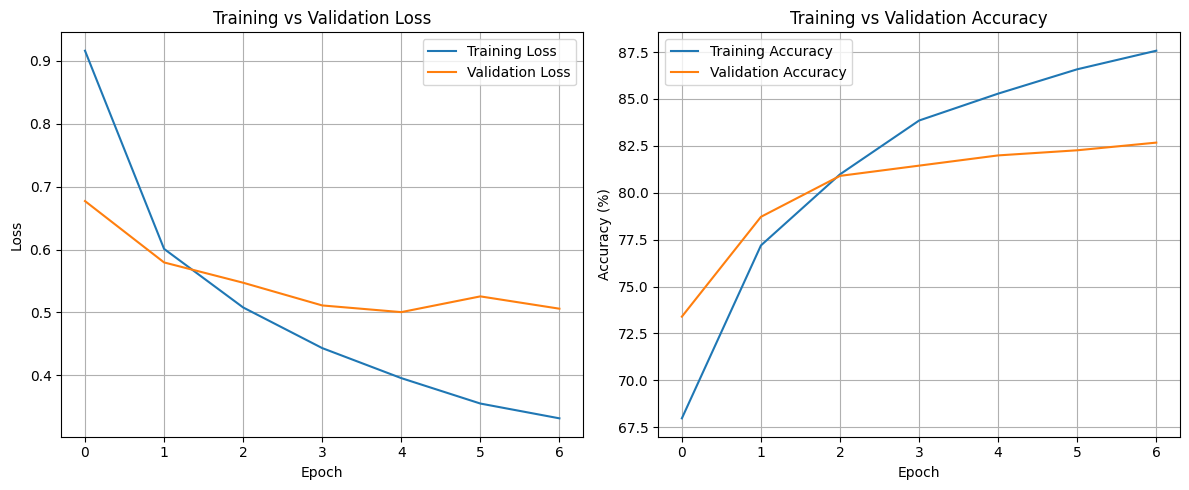

In [63]:
import matplotlib.pyplot as plt

# ==========================================
# TRAINING & VALIDATION CURVES
# ==========================================

plt.figure(figsize=(12, 5))

# Loss
plt.subplot(1, 2, 1)

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")

plt.legend()
plt.grid(True)


# Accuracy
plt.subplot(1, 2, 2)

plt.plot(train_accuracies, label="Training Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training vs Validation Accuracy")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Confusion Matrix:
[[351   7   3   0   0]
 [ 15  35  24   0   0]
 [  2  16 175   4   3]
 [  1   0  17  14   7]
 [  0   7  21   5  26]]


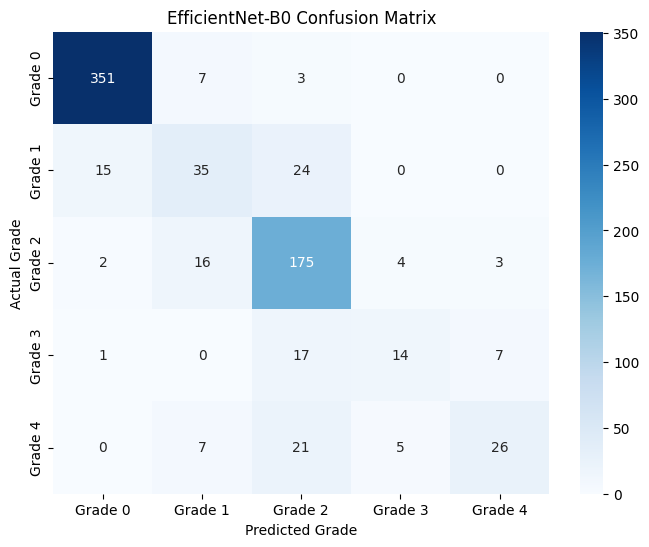

In [64]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# CONFUSION MATRIX
# ==========================================

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        all_predictions.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())


cm = confusion_matrix(all_labels, all_predictions)

print("Confusion Matrix:")
print(cm)


plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Grade 0", "Grade 1", "Grade 2", "Grade 3", "Grade 4"],
    yticklabels=["Grade 0", "Grade 1", "Grade 2", "Grade 3", "Grade 4"]
)

plt.xlabel("Predicted Grade")
plt.ylabel("Actual Grade")
plt.title("EfficientNet-B0 Confusion Matrix")

plt.show()

In [65]:
from sklearn.metrics import classification_report

# ==========================================
# CLASSIFICATION REPORT
# ==========================================

report = classification_report(
    all_labels,
    all_predictions,
    target_names=[
        "Grade 0",
        "Grade 1",
        "Grade 2",
        "Grade 3",
        "Grade 4"
    ],
    digits=4
)

print(report)

              precision    recall  f1-score   support

     Grade 0     0.9512    0.9723    0.9616       361
     Grade 1     0.5385    0.4730    0.5036        74
     Grade 2     0.7292    0.8750    0.7955       200
     Grade 3     0.6087    0.3590    0.4516        39
     Grade 4     0.7222    0.4407    0.5474        59

    accuracy                         0.8199       733
   macro avg     0.7100    0.6240    0.6519       733
weighted avg     0.8123    0.8199    0.8096       733



# **SAVE BEST MODEL withour aug**

In [66]:
# ==========================================
# SAVE BEST MODEL
# ==========================================

torch.save(
    model.state_dict(),
    "efficientnet-B0.pth"
)

print("EfficientNet-B0 model saved successfully!")

EfficientNet-B0 model saved successfully!


In [67]:
import os

print(os.path.abspath("efficientnet-B0.pth"))

/kaggle/working/efficientnet-B0.pth


# **DATA AUGMENTATION**

In [68]:
from torchvision import transforms

# ==========================================
# DATA AUGMENTATION
# ==========================================

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    # Randomly flip some retinal images
    transforms.RandomHorizontalFlip(p=0.5),

    # Slight rotation
    transforms.RandomRotation(10),

    # Slight changes in brightness/contrast/color
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.1
    ),

    transforms.ToTensor(),

    # ImageNet normalization for pretrained EfficientNet
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# Validation images are NOT randomly augmented
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Training augmentation ready!")
print("Validation preprocessing ready!")

Training augmentation ready!
Validation preprocessing ready!


# **RECREATE DATASETS WITH AUGMENTATION**

In [69]:
# ==========================================
# RECREATE DATASETS WITH AUGMENTATION
# ==========================================

train_dataset = DRDataset(
    train_df,
    image_dir,
    transform=train_transform
)

val_dataset = DRDataset(
    val_df,
    image_dir,
    transform=val_transform
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

Training images: 2929
Validation images: 733


# **RECREATE DATALOADERS**

In [26]:
# ==========================================
# RECREATE DATALOADERS
# ==========================================

from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 92
Validation batches: 23


# **RESET EFFICIENTNET-B0**

In [71]:
# ==========================================
# RESET EFFICIENTNET-B0
# ==========================================

from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
import torch.nn as nn

weights = EfficientNet_B0_Weights.DEFAULT

model = efficientnet_b0(weights=weights)

# Replace classifier with dropout + 5-class output
model.classifier[1] = nn.Sequential(
    nn.Dropout(p=0.4),
    nn.Linear(
        model.classifier[1].in_features,
        5
    )
)

model = model.to(device)

print("EfficientNet-B0 reset successfully!")
print("Model device:", next(model.parameters()).device)

EfficientNet-B0 reset successfully!
Model device: cuda:0


# **LOSS + OPTIMIZER for Efficientnet**

In [73]:
# ==========================================
# LOSS + OPTIMIZER
# ==========================================

import torch.nn as nn
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.0001,
    weight_decay=1e-4
)

print("Loss:", criterion)
print("Optimizer:", optimizer)

Loss: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0.0001
)


# **TRAIN EFFICIENTNET-B0 WITH AUGMENTATION (Augmented images → train_loader → EfficientNet-B0 → prediction → loss → backpropagation → update weights)**

In [74]:
# ==========================================
# TRAIN EFFICIENTNET-B0 WITH AUGMENTATION
# ==========================================

NUM_EPOCHS = 10
PATIENCE = 2

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

best_val_loss = float("inf")
best_model_weights = None
epochs_without_improvement = 0

for epoch in range(NUM_EPOCHS):

    # ==========================================
    # TRAINING
    # ==========================================
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clear old gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct / total


    # ==========================================
    # VALIDATION
    # ==========================================
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_loss = running_loss / len(val_loader)
    val_accuracy = 100 * correct / total


    # ==========================================
    # SAVE HISTORY
    # ==========================================

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)


    # ==========================================
    # EARLY STOPPING
    # ==========================================

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        # Save best weights
        best_model_weights = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }

        epochs_without_improvement = 0

        print("✓ New best validation loss!")

    else:

        epochs_without_improvement += 1


    # ==========================================
    # PRINT RESULTS
    # ==========================================

    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}%"
    )


    # ==========================================
    # STOP IF NO IMPROVEMENT
    # ==========================================

    if epochs_without_improvement >= PATIENCE:

        print(
            f"\nEarly stopping triggered after "
            f"{PATIENCE} epochs without improvement."
        )

        break


# ==========================================
# RESTORE BEST MODEL
# ==========================================

model.load_state_dict(best_model_weights)

model = model.to(device)

print("\nBest validation loss:", best_val_loss)
print("Best model weights restored.")

✓ New best validation loss!
Epoch [1/10] | Train Loss: 0.9778 | Train Acc: 66.06% | Val Loss: 0.6692 | Val Acc: 73.94%
✓ New best validation loss!
Epoch [2/10] | Train Loss: 0.6044 | Train Acc: 77.50% | Val Loss: 0.5610 | Val Acc: 77.90%
✓ New best validation loss!
Epoch [3/10] | Train Loss: 0.5121 | Train Acc: 80.98% | Val Loss: 0.5237 | Val Acc: 79.67%
✓ New best validation loss!
Epoch [4/10] | Train Loss: 0.4642 | Train Acc: 82.52% | Val Loss: 0.4956 | Val Acc: 81.72%
Epoch [5/10] | Train Loss: 0.4083 | Train Acc: 84.74% | Val Loss: 0.5164 | Val Acc: 82.40%
✓ New best validation loss!
Epoch [6/10] | Train Loss: 0.3693 | Train Acc: 86.00% | Val Loss: 0.4725 | Val Acc: 81.86%
Epoch [7/10] | Train Loss: 0.3255 | Train Acc: 87.50% | Val Loss: 0.4929 | Val Acc: 81.17%
Epoch [8/10] | Train Loss: 0.2890 | Train Acc: 89.86% | Val Loss: 0.5226 | Val Acc: 82.81%

Early stopping triggered after 2 epochs without improvement.

Best validation loss: 0.4724800094314244
Best model weights restored.

# **EVALUATE BEST EFFICIENTNET-B0**

In [77]:
# ==========================================
# EVALUATE BEST EFFICIENTNET-B0
# ==========================================

from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())


# ==========================================
# CLASSIFICATION REPORT
# ==========================================

print("Classification Report:\n")

print(
    classification_report(
        all_labels,
        all_predictions,
        digits=4
    )
)


# ==========================================
# CONFUSION MATRIX
# ==========================================

cm = confusion_matrix(
    all_labels,
    all_predictions
)

print("\nConfusion Matrix:\n")
print(cm)

Classification Report:

              precision    recall  f1-score   support

           0     0.9669    0.9695    0.9682       361
           1     0.5942    0.5541    0.5734        74
           2     0.7296    0.8500    0.7852       200
           3     0.4000    0.3077    0.3478        39
           4     0.6923    0.4576    0.5510        59

    accuracy                         0.8186       733
   macro avg     0.6766    0.6278    0.6451       733
weighted avg     0.8122    0.8186    0.8118       733


Confusion Matrix:

[[350   8   3   0   0]
 [ 11  41  21   1   0]
 [  1  14 170  11   4]
 [  0   0  19  12   8]
 [  0   6  20   6  27]]


# **SAVE BEST EFFICIENTNET-B0 + AUGMENTATION**

In [78]:
# ==========================================
# SAVE BEST EFFICIENTNET-B0 + AUGMENTATION
# ==========================================

MODEL_PATH = "/kaggle/working/efficientnet-B0-augmentation.pth"

torch.save(
    model.state_dict(),
    MODEL_PATH
)

print("Model saved successfully!")
print("Saved at:", MODEL_PATH)

Model saved successfully!
Saved at: /kaggle/working/efficientnet-B0-augmentation.pth


In [79]:
import os

print(os.path.exists("/kaggle/working/efficientnet-B0-augmentation.pth"))

True


In [80]:
import os

print(os.listdir("/kaggle/working"))

['.virtual_documents', 'convnext-tiny.pth', 'efficientnet-B0-augmentation.pth', 'efficientnet-B0.pth']


# **LOAD CONVNEXT-TINY**

In [38]:
# ==========================================
# LOAD CONVNEXT-TINY
# ==========================================

import torch
import torch.nn as nn
from torchvision.models import convnext_tiny, ConvNeXt_Tiny_Weights

# Load pretrained ConvNeXt-Tiny
weights = ConvNeXt_Tiny_Weights.DEFAULT

convnext_model = convnext_tiny(weights=weights)

# Replace the final classifier
num_features = convnext_model.classifier[2].in_features

convnext_model.classifier[2] = nn.Sequential(
    nn.Dropout(p=0.4),
    nn.Linear(num_features, 5)
)

# Move model to GPU
convnext_model = convnext_model.to(device)

print("ConvNeXt-Tiny loaded successfully!")
print("Number of output classes:", 5)
print("Model device:", next(convnext_model.parameters()).device)

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 222MB/s] 


ConvNeXt-Tiny loaded successfully!
Number of output classes: 5
Model device: cuda:0


# **CONVNEXT-TINY LOSS + OPTIMIZER**

In [39]:
# ==========================================
# CONVNEXT-TINY LOSS + OPTIMIZER
# ==========================================

criterion_convnext = nn.CrossEntropyLoss()

optimizer_convnext = torch.optim.Adam(
    convnext_model.parameters(),
    lr=0.0001,
    weight_decay=1e-4
)

print("Loss function:", criterion_convnext)
print("Optimizer:", optimizer_convnext)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0.0001
)


# **TRAIN CONVNEXT-TINY**

In [83]:
# ==========================================
# TRAIN CONVNEXT-TINY
# ==========================================

NUM_EPOCHS = 10
PATIENCE = 2

convnext_train_losses = []
convnext_val_losses = []
convnext_train_accuracies = []
convnext_val_accuracies = []

best_val_loss = float("inf")
best_model_weights = None
epochs_without_improvement = 0


for epoch in range(NUM_EPOCHS):

    # ==========================================
    # TRAINING
    # ==========================================

    convnext_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer_convnext.zero_grad()

        # Forward pass
        outputs = convnext_model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer_convnext.step()

        running_loss += loss.item()

        # Predictions
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()


    train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct / total


    # ==========================================
    # VALIDATION
    # ==========================================

    convnext_model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = convnext_model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()


    val_loss = running_loss / len(val_loader)
    val_accuracy = 100 * correct / total


    # ==========================================
    # SAVE HISTORY
    # ==========================================

    convnext_train_losses.append(train_loss)
    convnext_val_losses.append(val_loss)

    convnext_train_accuracies.append(train_accuracy)
    convnext_val_accuracies.append(val_accuracy)


    # ==========================================
    # EARLY STOPPING
    # ==========================================

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        # Save best model weights
        best_model_weights = {
            k: v.cpu().clone()
            for k, v in convnext_model.state_dict().items()
        }

        epochs_without_improvement = 0

        print("✓ New best validation loss!")

    else:

        epochs_without_improvement += 1


    # ==========================================
    # PRINT RESULTS
    # ==========================================

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}%"
    )


    # ==========================================
    # CHECK EARLY STOPPING
    # ==========================================

    if epochs_without_improvement >= PATIENCE:

        print(
            f"\nEarly stopping triggered after "
            f"{PATIENCE} epochs without improvement."
        )

        break


# ==========================================
# RESTORE BEST MODEL
# ==========================================

convnext_model.load_state_dict(best_model_weights)

convnext_model = convnext_model.to(device)

print("\nBest validation loss:", best_val_loss)
print("Best ConvNeXt-Tiny weights restored.")

✓ New best validation loss!
Epoch [1/10] | Train Loss: 0.7227 | Train Acc: 72.79% | Val Loss: 0.5689 | Val Acc: 78.99%
Epoch [2/10] | Train Loss: 0.4785 | Train Acc: 81.91% | Val Loss: 0.6511 | Val Acc: 73.12%
✓ New best validation loss!
Epoch [3/10] | Train Loss: 0.4373 | Train Acc: 82.93% | Val Loss: 0.5049 | Val Acc: 82.40%
✓ New best validation loss!
Epoch [4/10] | Train Loss: 0.3850 | Train Acc: 85.15% | Val Loss: 0.4410 | Val Acc: 83.77%
Epoch [5/10] | Train Loss: 0.3398 | Train Acc: 86.92% | Val Loss: 0.4695 | Val Acc: 82.54%
Epoch [6/10] | Train Loss: 0.2848 | Train Acc: 89.55% | Val Loss: 0.4634 | Val Acc: 83.63%

Early stopping triggered after 2 epochs without improvement.

Best validation loss: 0.440968359294145
Best ConvNeXt-Tiny weights restored.


# **SAVE BEST CONVNEXT-TINY MODEL**

In [84]:
# ==========================================
# SAVE BEST CONVNEXT-TINY MODEL
# ==========================================

torch.save(
    convnext_model.state_dict(),
    "/kaggle/working/convnext-tiny.pth"
)

print("ConvNeXt-Tiny model saved successfully!")

ConvNeXt-Tiny model saved successfully!


In [85]:
import os

print(os.path.exists("/kaggle/working/convnext-tiny.pth"))

True


# **CONVNEXT-TINY VALIDATION PREDICTIONS**

In [86]:
# ==========================================
# CONVNEXT-TINY VALIDATION PREDICTIONS
# ==========================================

from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

convnext_model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = convnext_model(images)

        _, predictions = torch.max(outputs, 1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())


print("Classification Report - ConvNeXt-Tiny")
print(
    classification_report(
        all_labels,
        all_predictions,
        digits=4
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        all_labels,
        all_predictions
    )
)

Classification Report - ConvNeXt-Tiny
              precision    recall  f1-score   support

           0     0.9914    0.9612    0.9761       361
           1     0.6000    0.7297    0.6585        74
           2     0.7373    0.8700    0.7982       200
           3     0.6364    0.3590    0.4590        39
           4     0.7143    0.4237    0.5319        59

    accuracy                         0.8377       733
   macro avg     0.7359    0.6687    0.6847       733
weighted avg     0.8414    0.8377    0.8322       733


Confusion Matrix:
[[347  12   2   0   0]
 [  2  54  18   0   0]
 [  0  19 174   4   3]
 [  1   1  16  14   7]
 [  0   4  26   4  25]]


# **EVALUATE EFFICIENTNET-B0**

In [87]:
# ==========================================
# EVALUATE EFFICIENTNET-B0
# ==========================================

from sklearn.metrics import classification_report, confusion_matrix

model.eval()

all_labels_eff = []
all_predictions_eff = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Model prediction
        outputs = model(images)

        # Get predicted class
        _, predictions = torch.max(outputs, 1)

        # Store results
        all_labels_eff.extend(labels.cpu().numpy())
        all_predictions_eff.extend(predictions.cpu().numpy())


# ==========================================
# CLASSIFICATION REPORT
# ==========================================

print("Classification Report - EfficientNet-B0\n")

print(
    classification_report(
        all_labels_eff,
        all_predictions_eff,
        digits=4
    )
)


# ==========================================
# CONFUSION MATRIX
# ==========================================

print("\nConfusion Matrix:\n")

print(
    confusion_matrix(
        all_labels_eff,
        all_predictions_eff
    )
)

Classification Report - EfficientNet-B0

              precision    recall  f1-score   support

           0     0.9669    0.9695    0.9682       361
           1     0.5942    0.5541    0.5734        74
           2     0.7296    0.8500    0.7852       200
           3     0.4000    0.3077    0.3478        39
           4     0.6923    0.4576    0.5510        59

    accuracy                         0.8186       733
   macro avg     0.6766    0.6278    0.6451       733
weighted avg     0.8122    0.8186    0.8118       733


Confusion Matrix:

[[350   8   3   0   0]
 [ 11  41  21   1   0]
 [  1  14 170  11   4]
 [  0   0  19  12   8]
 [  0   6  20   6  27]]


In [88]:
import os

print("Saved model files:")

for root, dirs, files in os.walk("/kaggle/working"):
    for file in files:
        if file.endswith((".pth", ".pt", ".ckpt")):
            print(os.path.join(root, file))

Saved model files:
/kaggle/working/convnext-tiny.pth
/kaggle/working/efficientnet-B0-augmentation.pth
/kaggle/working/efficientnet-B0.pth


# **ENSEMBLE: EFFICIENTNET-B0 + CONVNEXT-TINY**

In [54]:
# ==========================================
# ENSEMBLE: EFFICIENTNET-B0 + CONVNEXT-TINY
# ==========================================

import torch
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Put both models in evaluation mode
model.eval()
convnext_model.eval()

ensemble_labels = []
ensemble_predictions = []

with torch.no_grad():

    for images, labels in val_loader:

        # Move data to GPU
        images = images.to(device)
        labels = labels.to(device)

        # ------------------------------------------
        # EfficientNet-B0 prediction
        # ------------------------------------------
        eff_outputs = model(images)

        # Convert logits to probabilities
        eff_probs = torch.softmax(eff_outputs, dim=1)

        # ------------------------------------------
        # ConvNeXt-Tiny prediction
        # ------------------------------------------
        conv_outputs = convnext_model(images)

        # Convert logits to probabilities
        conv_probs = torch.softmax(conv_outputs, dim=1)

        # ------------------------------------------
        # Average the two models
        # ------------------------------------------
        ensemble_probs = (eff_probs + conv_probs) / 2

        # Final predicted class
        _, predictions = torch.max(ensemble_probs, 1)

        # Store results
        ensemble_labels.extend(labels.cpu().numpy())
        ensemble_predictions.extend(predictions.cpu().numpy())


# ==========================================
# ENSEMBLE ACCURACY
# ==========================================

ensemble_accuracy = accuracy_score(
    ensemble_labels,
    ensemble_predictions
)

print("Ensemble Accuracy:",
      f"{ensemble_accuracy * 100:.2f}%")
      

# ==========================================
# CLASSIFICATION REPORT
# ==========================================

print("\nClassification Report - Ensemble\n")

print(
    classification_report(
        ensemble_labels,
        ensemble_predictions,
        digits=4
    )
)


# ==========================================
# CONFUSION MATRIX
# ==========================================

print("\nConfusion Matrix - Ensemble:\n")

print(
    confusion_matrix(
        ensemble_labels,
        ensemble_predictions
    )
)

Ensemble Accuracy: 84.86%

Classification Report - Ensemble

              precision    recall  f1-score   support

           0     0.9859    0.9668    0.9762       361
           1     0.7031    0.6081    0.6522        74
           2     0.7713    0.8600    0.8132       200
           3     0.4889    0.5641    0.5238        39
           4     0.7234    0.5763    0.6415        59

    accuracy                         0.8486       733
   macro avg     0.7345    0.7150    0.7214       733
weighted avg     0.8512    0.8486    0.8480       733


Confusion Matrix - Ensemble:

[[349   8   4   0   0]
 [  4  45  24   0   1]
 [  1   7 172  14   6]
 [  0   0  11  22   6]
 [  0   4  12   9  34]]


# **SAVE FINAL MODELS**

In [91]:
# ==========================================
# SAVE FINAL MODELS
# ==========================================

torch.save(
    model.state_dict(),
    "/kaggle/working/efficientnet-B0.pth"
)

torch.save(
    convnext_model.state_dict(),
    "/kaggle/working/convnext-tiny.pth"
)

print("EfficientNet-B0 saved.")
print("ConvNeXt-Tiny saved.")
print("Ensemble uses both models with 50-50 probability averaging.")

EfficientNet-B0 saved.
ConvNeXt-Tiny saved.
Ensemble uses both models with 50-50 probability averaging.


# **ENSEMBLE CONFUSION MATRIX VISUALIZATION**

<Figure size 700x700 with 0 Axes>

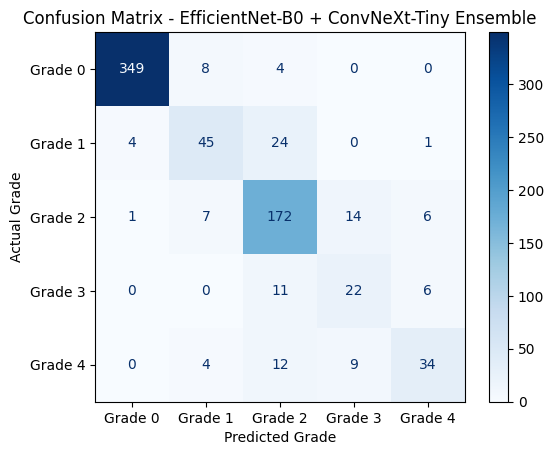

In [56]:
# ==========================================
# ENSEMBLE CONFUSION MATRIX VISUALIZATION
# ==========================================

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    ensemble_labels,
    ensemble_predictions
)

plt.figure(figsize=(7, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Grade 0", "Grade 1", "Grade 2", "Grade 3", "Grade 4"]
)

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Confusion Matrix - EfficientNet-B0 + ConvNeXt-Tiny Ensemble")
plt.xlabel("Predicted Grade")
plt.ylabel("Actual Grade")
plt.show()

# **ENSEMBLE CONFUSION MATRIX**

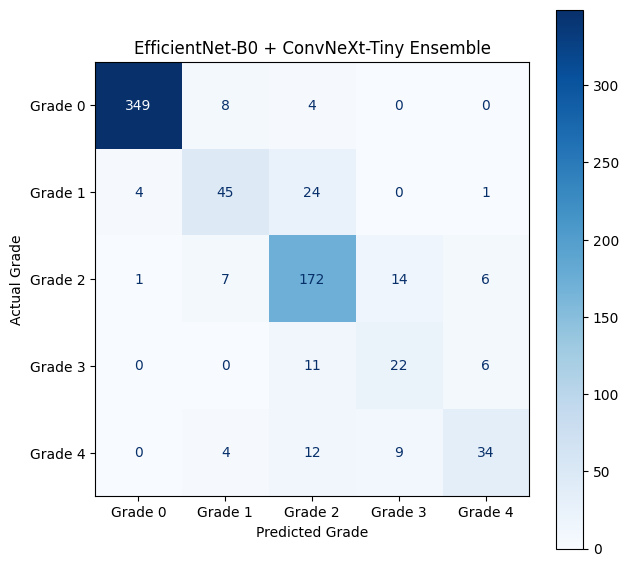

In [57]:
# ==========================================
# ENSEMBLE CONFUSION MATRIX
# ==========================================

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    ensemble_labels,
    ensemble_predictions
)

fig, ax = plt.subplots(figsize=(7, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Grade 0",
        "Grade 1",
        "Grade 2",
        "Grade 3",
        "Grade 4"
    ]
)

disp.plot(
    ax=ax,
    values_format="d",
    cmap="Blues"
)

plt.title(
    "EfficientNet-B0 + ConvNeXt-Tiny Ensemble"
)

plt.xlabel("Predicted Grade")
plt.ylabel("Actual Grade")

plt.show()

# **GRID SEARCH - WEIGHTED SOFT VOTING**

In [58]:
# ==========================================
# GRID SEARCH - WEIGHTED SOFT VOTING
# EfficientNet-B0 + ConvNeXt-Tiny
# ==========================================

from sklearn.metrics import accuracy_score
import numpy as np
import torch

model.eval()
convnext_model.eval()

# Store probability predictions
eff_probs_all = []
conv_probs_all = []
labels_all = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)
        labels = labels.to(device)

        # -----------------------------
        # EfficientNet-B0
        # -----------------------------
        eff_outputs = model(images)
        eff_probs = torch.softmax(eff_outputs, dim=1)

        # -----------------------------
        # ConvNeXt-Tiny
        # -----------------------------
        conv_outputs = convnext_model(images)
        conv_probs = torch.softmax(conv_outputs, dim=1)

        # Store on CPU
        eff_probs_all.append(eff_probs.cpu())
        conv_probs_all.append(conv_probs.cpu())
        labels_all.append(labels.cpu())


# Combine all batches
eff_probs_all = torch.cat(eff_probs_all)
conv_probs_all = torch.cat(conv_probs_all)
labels_all = torch.cat(labels_all)


# ==========================================
# GRID SEARCH
# ==========================================

best_accuracy = 0.0
best_eff_weight = 0.0
best_conv_weight = 0.0

results = []

# Test weights from 0.0 to 1.0
# Step = 0.05

for eff_weight in np.arange(0.0, 1.01, 0.05):

    conv_weight = 1.0 - eff_weight

    # Weighted probability combination
    weighted_probs = (
        eff_weight * eff_probs_all
        + conv_weight * conv_probs_all
    )

    # Final prediction
    predictions = torch.argmax(
        weighted_probs,
        dim=1
    )

    accuracy = accuracy_score(
        labels_all.numpy(),
        predictions.numpy()
    )

    results.append(
        (
            round(eff_weight, 2),
            round(conv_weight, 2),
            accuracy * 100
        )
    )

    # Check best result
    if accuracy > best_accuracy:

        best_accuracy = accuracy
        best_eff_weight = eff_weight
        best_conv_weight = conv_weight


# ==========================================
# DISPLAY RESULTS
# ==========================================

print("==========================================")
print("GRID SEARCH RESULTS")
print("==========================================")

for eff_weight, conv_weight, accuracy in results:

    print(
        f"EfficientNet: {eff_weight:.2f} | "
        f"ConvNeXt: {conv_weight:.2f} | "
        f"Accuracy: {accuracy:.2f}%"
    )


print("\n==========================================")
print("BEST WEIGHTED ENSEMBLE")
print("==========================================")

print(
    f"EfficientNet-B0 weight: {best_eff_weight:.2f}"
)

print(
    f"ConvNeXt-Tiny weight: {best_conv_weight:.2f}"
)

print(
    f"Best Validation Accuracy: "
    f"{best_accuracy * 100:.2f}%"
)

GRID SEARCH RESULTS
EfficientNet: 0.00 | ConvNeXt: 1.00 | Accuracy: 82.81%
EfficientNet: 0.05 | ConvNeXt: 0.95 | Accuracy: 83.22%
EfficientNet: 0.10 | ConvNeXt: 0.90 | Accuracy: 83.36%
EfficientNet: 0.15 | ConvNeXt: 0.85 | Accuracy: 83.08%
EfficientNet: 0.20 | ConvNeXt: 0.80 | Accuracy: 83.49%
EfficientNet: 0.25 | ConvNeXt: 0.75 | Accuracy: 83.77%
EfficientNet: 0.30 | ConvNeXt: 0.70 | Accuracy: 83.77%
EfficientNet: 0.35 | ConvNeXt: 0.65 | Accuracy: 83.90%
EfficientNet: 0.40 | ConvNeXt: 0.60 | Accuracy: 84.72%
EfficientNet: 0.45 | ConvNeXt: 0.55 | Accuracy: 84.58%
EfficientNet: 0.50 | ConvNeXt: 0.50 | Accuracy: 84.86%
EfficientNet: 0.55 | ConvNeXt: 0.45 | Accuracy: 84.31%
EfficientNet: 0.60 | ConvNeXt: 0.40 | Accuracy: 84.17%
EfficientNet: 0.65 | ConvNeXt: 0.35 | Accuracy: 83.90%
EfficientNet: 0.70 | ConvNeXt: 0.30 | Accuracy: 83.49%
EfficientNet: 0.75 | ConvNeXt: 0.25 | Accuracy: 83.08%
EfficientNet: 0.80 | ConvNeXt: 0.20 | Accuracy: 82.81%
EfficientNet: 0.85 | ConvNeXt: 0.15 | Accurac

# **PREPARE MODELS FOR TTA**

In [68]:
# ==========================================
# PREPARE MODELS FOR TTA
# ==========================================

model.eval()
convnext_model.eval()

print("EfficientNet-B0:", next(model.parameters()).device)
print("ConvNeXt-Tiny:", next(convnext_model.parameters()).device)
print("Both models ready for TTA!")

EfficientNet-B0: cuda:0
ConvNeXt-Tiny: cuda:0
Both models ready for TTA!


# **TEST-TIME AUGMENTATION (TTA)**

In [60]:
# ==========================================
# TEST-TIME AUGMENTATION (TTA)
# Original + Horizontal Flip
# ==========================================

import torch

model.eval()
convnext_model.eval()

tta_predictions = []
tta_labels = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)
        labels = labels.to(device)

        # ----------------------------------
        # ORIGINAL IMAGES
        # ----------------------------------

        eff_original = torch.softmax(
            model(images), dim=1
        )

        conv_original = torch.softmax(
            convnext_model(images), dim=1
        )


        # ----------------------------------
        # HORIZONTAL FLIP
        # ----------------------------------

        flipped_images = torch.flip(
            images,
            dims=[3]   # flip width
        )

        eff_flip = torch.softmax(
            model(flipped_images), dim=1
        )

        conv_flip = torch.softmax(
            convnext_model(flipped_images), dim=1
        )


        # ----------------------------------
        # TTA FOR EACH MODEL
        # ----------------------------------

        eff_tta = (
            eff_original + eff_flip
        ) / 2

        conv_tta = (
            conv_original + conv_flip
        ) / 2


        # ----------------------------------
        # 50:50 SOFT-VOTING ENSEMBLE
        # ----------------------------------

        ensemble_tta = (
            0.5 * eff_tta +
            0.5 * conv_tta
        )


        # ----------------------------------
        # FINAL PREDICTIONS
        # ----------------------------------

        predictions = torch.argmax(
            ensemble_tta,
            dim=1
        )

        tta_predictions.extend(
            predictions.cpu().numpy()
        )

        tta_labels.extend(
            labels.cpu().numpy()
        )


print("TTA prediction completed!")
print("Total validation images:", len(tta_labels))

TTA prediction completed!
Total validation images: 733


# **EVALUATE TTA ENSEMBLE**

In [61]:
# ==========================================
# EVALUATE TTA ENSEMBLE
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Calculate accuracy
tta_accuracy = accuracy_score(
    tta_labels,
    tta_predictions
)

print("=" * 50)
print("TTA ENSEMBLE RESULTS")
print("=" * 50)

print(f"\nTTA Ensemble Accuracy: {tta_accuracy * 100:.2f}%")

print("\nClassification Report - TTA Ensemble\n")

print(
    classification_report(
        tta_labels,
        tta_predictions,
        digits=4
    )
)

print("\nConfusion Matrix - TTA Ensemble:\n")

print(
    confusion_matrix(
        tta_labels,
        tta_predictions
    )
)

# Compare with previous ensemble
previous_accuracy = 84.86

improvement = (
    tta_accuracy * 100
) - previous_accuracy

print("\n" + "=" * 50)
print("COMPARISON")
print("=" * 50)

print(f"Previous Ensemble : {previous_accuracy:.2f}%")
print(f"TTA Ensemble      : {tta_accuracy * 100:.2f}%")
print(f"Improvement       : {improvement:+.2f}%")

TTA ENSEMBLE RESULTS

TTA Ensemble Accuracy: 84.45%

Classification Report - TTA Ensemble

              precision    recall  f1-score   support

           0     0.9803    0.9640    0.9721       361
           1     0.6719    0.5811    0.6232        74
           2     0.7703    0.8550    0.8104       200
           3     0.4783    0.5641    0.5176        39
           4     0.7609    0.5932    0.6667        59

    accuracy                         0.8445       733
   macro avg     0.7323    0.7115    0.7180       733
weighted avg     0.8475    0.8445    0.8440       733


Confusion Matrix - TTA Ensemble:

[[348  10   3   0   0]
 [  6  43  25   0   0]
 [  1   7 171  16   5]
 [  0   0  11  22   6]
 [  0   4  12   8  35]]

COMPARISON
Previous Ensemble : 84.86%
TTA Ensemble      : 84.45%
Improvement       : -0.41%


# **EFFICIENTNET-B0 - FINE-TUNING SETUP**

In [70]:
# ==========================================
# EFFICIENTNET-B0 - FINE-TUNING SETUP
# ==========================================

import torch.optim as optim

# Optimizer with lower learning rate
optimizer = optim.Adam(
    model.parameters(),
    lr=1e-5,
    weight_decay=1e-4
)

# Reduce learning rate when validation loss stops improving
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=1
)

print("Optimizer:", optimizer)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Weight decay:", optimizer.param_groups[0]["weight_decay"])
print("Scheduler: ReduceLROnPlateau")

Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 1e-05
    maximize: False
    weight_decay: 0.0001
)
Learning rate: 1e-05
Weight decay: 0.0001
Scheduler: ReduceLROnPlateau


# **FINE-TUNE EFFICIENTNET-B0**

In [63]:
# ==========================================
# FINE-TUNE EFFICIENTNET-B0
# LOWER LR + SCHEDULER + EARLY STOPPING
# ==========================================

import copy
import torch

NUM_EPOCHS = 20
PATIENCE = 3

train_losses_ft = []
val_losses_ft = []
train_accuracies_ft = []
val_accuracies_ft = []

best_val_loss = float("inf")
best_model_weights = copy.deepcopy(model.state_dict())
epochs_without_improvement = 0

for epoch in range(NUM_EPOCHS):

    # ==========================================
    # TRAINING
    # ==========================================

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct / total


    # ==========================================
    # VALIDATION
    # ==========================================

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_loss = running_loss / len(val_loader)
    val_accuracy = 100 * correct / total


    # ==========================================
    # LEARNING RATE SCHEDULER
    # ==========================================

    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]


    # ==========================================
    # SAVE HISTORY
    # ==========================================

    train_losses_ft.append(train_loss)
    val_losses_ft.append(val_loss)

    train_accuracies_ft.append(train_accuracy)
    val_accuracies_ft.append(val_accuracy)


    # ==========================================
    # CHECK BEST MODEL
    # ==========================================

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_model_weights = copy.deepcopy(
            model.state_dict()
        )

        epochs_without_improvement = 0

        print("✓ New best validation loss!")

    else:

        epochs_without_improvement += 1


    # ==========================================
    # PRINT RESULTS
    # ==========================================

    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}% | "
        f"LR: {current_lr:.7f}"
    )


    # ==========================================
    # EARLY STOPPING
    # ==========================================

    if epochs_without_improvement >= PATIENCE:

        print(
            f"\nEarly stopping triggered after "
            f"{PATIENCE} epochs without improvement."
        )

        break


# ==========================================
# RESTORE BEST MODEL
# ==========================================

model.load_state_dict(best_model_weights)
model = model.to(device)

print("\n==========================================")
print("FINE-TUNING COMPLETE")
print("==========================================")
print(f"Best validation loss: {best_val_loss:.4f}")
print("Best EfficientNet-B0 weights restored.")

✓ New best validation loss!
Epoch [1/20] | Train Loss: 0.3567 | Train Acc: 86.24% | Val Loss: 0.4889 | Val Acc: 82.13% | LR: 0.0000100
✓ New best validation loss!
Epoch [2/20] | Train Loss: 0.3541 | Train Acc: 86.45% | Val Loss: 0.4871 | Val Acc: 82.40% | LR: 0.0000100
✓ New best validation loss!
Epoch [3/20] | Train Loss: 0.3485 | Train Acc: 86.92% | Val Loss: 0.4869 | Val Acc: 82.26% | LR: 0.0000100
✓ New best validation loss!
Epoch [4/20] | Train Loss: 0.3294 | Train Acc: 87.85% | Val Loss: 0.4798 | Val Acc: 81.72% | LR: 0.0000100
Epoch [5/20] | Train Loss: 0.3337 | Train Acc: 87.71% | Val Loss: 0.4854 | Val Acc: 83.22% | LR: 0.0000100
Epoch [6/20] | Train Loss: 0.3170 | Train Acc: 87.50% | Val Loss: 0.4849 | Val Acc: 82.67% | LR: 0.0000050
Epoch [7/20] | Train Loss: 0.3097 | Train Acc: 88.56% | Val Loss: 0.4863 | Val Acc: 82.95% | LR: 0.0000050

Early stopping triggered after 3 epochs without improvement.

FINE-TUNING COMPLETE
Best validation loss: 0.4798
Best EfficientNet-B0 weigh

# **Focal loss**

In [71]:
# ==========================================
# FOCAL LOSS
# ==========================================

import torch
import torch.nn as nn
import torch.nn.functional as F


class FocalLoss(nn.Module):

    def __init__(self, alpha=1.0, gamma=2.0):
        super(FocalLoss, self).__init__()

        self.alpha = alpha
        self.gamma = gamma

    def forward(self, inputs, targets):

        # Standard cross entropy for each sample
        ce_loss = F.cross_entropy(
            inputs,
            targets,
            reduction="none"
        )

        # Probability of the correct class
        pt = torch.exp(-ce_loss)

        # Focal loss
        focal_loss = self.alpha * (1 - pt) ** self.gamma * ce_loss

        return focal_loss.mean()


criterion_focal = FocalLoss(
    alpha=1.0,
    gamma=2.0
)

print("Focal Loss created successfully!")

Focal Loss created successfully!


# **TRAIN EFFICIENTNET-B0 WITH FOCAL LOSS**

In [67]:
# ==========================================
# TRAIN EFFICIENTNET-B0 WITH FOCAL LOSS
# ==========================================

import copy
import torch

NUM_EPOCHS = 15
PATIENCE = 3

# Use the current EfficientNet-B0 model
# Make sure model is the EfficientNet-B0 model, NOT ConvNeXt
model = model.to(device)

# Optimizer
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-5,
    weight_decay=1e-4
)

# Learning-rate scheduler
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=1
)

# History
train_losses_focal = []
val_losses_focal = []
train_accuracies_focal = []
val_accuracies_focal = []

# Best model
best_val_loss_focal = float("inf")
best_model_weights_focal = copy.deepcopy(model.state_dict())

epochs_without_improvement = 0


for epoch in range(NUM_EPOCHS):

    # ==========================================
    # TRAINING
    # ==========================================

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        # FOCAL LOSS
        loss = criterion_focal(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()


    train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct / total


    # ==========================================
    # VALIDATION
    # ==========================================

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion_focal(outputs, labels)

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()


    val_loss = running_loss / len(val_loader)
    val_accuracy = 100 * correct / total


    # ==========================================
    # SCHEDULER
    # ==========================================

    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]


    # ==========================================
    # SAVE HISTORY
    # ==========================================

    train_losses_focal.append(train_loss)
    val_losses_focal.append(val_loss)

    train_accuracies_focal.append(train_accuracy)
    val_accuracies_focal.append(val_accuracy)


    # ==========================================
    # BEST MODEL
    # ==========================================

    if val_loss < best_val_loss_focal:

        best_val_loss_focal = val_loss

        best_model_weights_focal = copy.deepcopy(
            model.state_dict()
        )

        epochs_without_improvement = 0

        print("✓ New best validation loss!")

    else:

        epochs_without_improvement += 1


    # ==========================================
    # RESULTS
    # ==========================================

    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}% | "
        f"LR: {current_lr:.7f}"
    )


    # ==========================================
    # EARLY STOPPING
    # ==========================================

    if epochs_without_improvement >= PATIENCE:

        print(
            f"\nEarly stopping triggered after "
            f"{PATIENCE} epochs without improvement."
        )

        break


# ==========================================
# RESTORE BEST FOCAL MODEL
# ==========================================

model.load_state_dict(best_model_weights_focal)
model = model.to(device)

print("\n==========================================")
print("FOCAL LOSS TRAINING COMPLETE")
print("==========================================")
print(
    f"Best validation loss: "
    f"{best_val_loss_focal:.4f}"
)
print("Best Focal EfficientNet-B0 weights restored.")

✓ New best validation loss!
Epoch [1/15] | Train Loss: 0.1498 | Train Acc: 87.74% | Val Loss: 0.2815 | Val Acc: 81.31% | LR: 0.0000100
Epoch [2/15] | Train Loss: 0.1477 | Train Acc: 88.19% | Val Loss: 0.2833 | Val Acc: 82.54% | LR: 0.0000100
✓ New best validation loss!
Epoch [3/15] | Train Loss: 0.1334 | Train Acc: 88.73% | Val Loss: 0.2689 | Val Acc: 81.99% | LR: 0.0000100
✓ New best validation loss!
Epoch [4/15] | Train Loss: 0.1329 | Train Acc: 89.18% | Val Loss: 0.2583 | Val Acc: 81.72% | LR: 0.0000100
Epoch [5/15] | Train Loss: 0.1304 | Train Acc: 89.38% | Val Loss: 0.2597 | Val Acc: 82.26% | LR: 0.0000100
Epoch [6/15] | Train Loss: 0.1285 | Train Acc: 88.53% | Val Loss: 0.2619 | Val Acc: 81.31% | LR: 0.0000050
Epoch [7/15] | Train Loss: 0.1185 | Train Acc: 89.55% | Val Loss: 0.2600 | Val Acc: 83.08% | LR: 0.0000050

Early stopping triggered after 3 epochs without improvement.

FOCAL LOSS TRAINING COMPLETE
Best validation loss: 0.2583
Best Focal EfficientNet-B0 weights restored.


In [11]:
# ==========================================
# SET DEVICE
# ==========================================

import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cuda


# **ORDINAL EFFICIENTNET-B0**

In [72]:
# ==========================================
# ORDINAL EFFICIENTNET-B0
# ==========================================

import torch
import torch.nn as nn
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

# Load pretrained EfficientNet-B0
ordinal_model = efficientnet_b0(
    weights=EfficientNet_B0_Weights.DEFAULT
)

# Get number of input features
num_features = ordinal_model.classifier[1].in_features

# Replace normal 5-class classifier
# with 4 ordinal outputs
ordinal_model.classifier = nn.Sequential(
    nn.Dropout(p=0.4),
    nn.Linear(num_features, 4)
)

# Move model to GPU
ordinal_model = ordinal_model.to(device)

print("Ordinal EfficientNet-B0 created successfully!")
print("Number of ordinal outputs:", 4)
print("Model device:", next(ordinal_model.parameters()).device)

Ordinal EfficientNet-B0 created successfully!
Number of ordinal outputs: 4
Model device: cuda:0


# **ORDINAL TARGET + LOSS**

In [73]:
# ==========================================
# ORDINAL TARGET + LOSS
# ==========================================

import torch.nn as nn

def create_ordinal_targets(labels):
    """
    Convert DR grades 0-4 into 4 ordinal targets.

    Grade 0 -> [0, 0, 0, 0]
    Grade 1 -> [1, 0, 0, 0]
    Grade 2 -> [1, 1, 0, 0]
    Grade 3 -> [1, 1, 1, 0]
    Grade 4 -> [1, 1, 1, 1]
    """

    ordinal_targets = torch.stack(
        [
            (labels > 0).float(),
            (labels > 1).float(),
            (labels > 2).float(),
            (labels > 3).float()
        ],
        dim=1
    )

    return ordinal_targets


# Ordinal loss
ordinal_criterion = nn.BCEWithLogitsLoss()


# Test
test_labels = torch.tensor([0, 1, 2, 3, 4])

test_targets = create_ordinal_targets(test_labels)

print("Original grades:")
print(test_labels)

print("\nOrdinal targets:")
print(test_targets)

print("\nOrdinal loss created successfully!")

Original grades:
tensor([0, 1, 2, 3, 4])

Ordinal targets:
tensor([[0., 0., 0., 0.],
        [1., 0., 0., 0.],
        [1., 1., 0., 0.],
        [1., 1., 1., 0.],
        [1., 1., 1., 1.]])

Ordinal loss created successfully!


In [17]:
# ==========================================
# CHECK CURRENT DATA VARIABLES
# ==========================================

print("Variables related to DATA / LOADER:")
print("=" * 50)

current_variables = list(globals().items())

for name, obj in current_variables:

    if any(word in name.lower() for word in [
        "train",
        "val",
        "test",
        "loader",
        "dataset",
        "data"
    ]):

        print(
            name,
            "->",
            type(obj).__name__
        )

Variables related to DATA / LOADER:
__loader__ -> NoneType
test_labels -> Tensor
test_targets -> Tensor
ordinal_train_losses -> list
ordinal_val_losses -> list
ordinal_train_accuracies -> list
ordinal_val_accuracies -> list
best_ordinal_val_loss -> float
DataLoader -> type


In [42]:
print("train_loader:", type(train_loader))
print("val_loader:", type(val_loader))

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

train_loader: <class 'torch.utils.data.dataloader.DataLoader'>
val_loader: <class 'torch.utils.data.dataloader.DataLoader'>
Train batches: 92
Validation batches: 23


In [74]:
# ============================================================
# FIND THE ACTUAL DR DATASET IN KAGGLE
# ============================================================

import os
import pandas as pd

print("KAGGLE INPUT DATASETS")
print("=" * 60)

for root, dirs, files in os.walk("/kaggle/input"):
    level = root.replace("/kaggle/input", "").count(os.sep)

    # Keep output manageable
    if level <= 2:
        print(root)

        for f in files[:10]:
            print("   ", f)

print("\nCSV FILES")
print("=" * 60)

csv_files = []

for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        if f.lower().endswith(".csv"):
            path = os.path.join(root, f)
            csv_files.append(path)
            print(path)

print("\nTOTAL CSV FILES:", len(csv_files))


# ------------------------------------------------------------
# SHOW CSV STRUCTURE
# ------------------------------------------------------------

for csv_path in csv_files:

    try:
        df = pd.read_csv(csv_path)

        print("\n" + "=" * 60)
        print("FILE:", csv_path)
        print("SHAPE:", df.shape)
        print("COLUMNS:", list(df.columns))
        print(df.head())

    except Exception as e:
        print("Could not read:", csv_path)
        print("Error:", e)

KAGGLE INPUT DATASETS
/kaggle/input
/kaggle/input/competitions
/kaggle/input/competitions/aptos2019-blindness-detection
    sample_submission.csv
    train.csv
    test.csv

CSV FILES
/kaggle/input/competitions/aptos2019-blindness-detection/sample_submission.csv
/kaggle/input/competitions/aptos2019-blindness-detection/train.csv
/kaggle/input/competitions/aptos2019-blindness-detection/test.csv

TOTAL CSV FILES: 3

FILE: /kaggle/input/competitions/aptos2019-blindness-detection/sample_submission.csv
SHAPE: (1928, 2)
COLUMNS: ['id_code', 'diagnosis']
        id_code  diagnosis
0  0005cfc8afb6          0
1  003f0afdcd15          0
2  006efc72b638          0
3  00836aaacf06          0
4  009245722fa4          0

FILE: /kaggle/input/competitions/aptos2019-blindness-detection/train.csv
SHAPE: (3662, 2)
COLUMNS: ['id_code', 'diagnosis']
        id_code  diagnosis
0  000c1434d8d7          2
1  001639a390f0          4
2  0024cdab0c1e          1
3  002c21358ce6          0
4  005b95c28852          

In [27]:
# ============================================================
# FIND APTOS IMAGE DIRECTORY
# ============================================================

import os

print("Searching for APTOS image files...")
print("=" * 60)

image_extensions = (".png", ".jpg", ".jpeg")

found_images = []

for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        if f.lower().endswith(image_extensions):
            found_images.append(os.path.join(root, f))

            # Stop after finding 10 examples
            if len(found_images) >= 10:
                break

    if len(found_images) >= 10:
        break

print("Number of example images found:", len(found_images))

for path in found_images:
    print(path)

Searching for APTOS image files...
Number of example images found: 10
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/ef476be214d4.png
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/6dcde47060f9.png
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/ec363f48867b.png
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/17f6c7072f61.png
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/b49b2fac2514.png
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/af6166d57f13.png
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/8d13c46e7d75.png
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/c3b15bf9b4bc.png
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/be68322c7223.png
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/88e4399d207c.png


# **TRAIN ORDINAL EFFICIENTNET-B0**

In [75]:
# ==========================================
# TRAIN ORDINAL EFFICIENTNET-B0
# ==========================================

import copy
import torch

NUM_EPOCHS = 15
PATIENCE = 3

# ------------------------------------------
# OPTIMIZER
# ------------------------------------------

ordinal_optimizer = torch.optim.AdamW(
    ordinal_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

# ------------------------------------------
# LEARNING RATE SCHEDULER
# ------------------------------------------

ordinal_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    ordinal_optimizer,
    mode="min",
    factor=0.5,
    patience=1
)

# ------------------------------------------
# HISTORY
# ------------------------------------------

ordinal_train_losses = []
ordinal_val_losses = []

ordinal_train_accuracies = []
ordinal_val_accuracies = []

# ------------------------------------------
# BEST MODEL
# ------------------------------------------

best_ordinal_val_loss = float("inf")

best_ordinal_weights = copy.deepcopy(
    ordinal_model.state_dict()
)

epochs_without_improvement = 0


# ==========================================
# TRAINING
# ==========================================

for epoch in range(NUM_EPOCHS):

    ordinal_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Convert 0-4 labels into ordinal targets
        ordinal_targets = create_ordinal_targets(labels)

        # Clear gradients
        ordinal_optimizer.zero_grad()

        # Forward pass
        outputs = ordinal_model(images)

        # Ordinal loss
        loss = ordinal_criterion(
            outputs,
            ordinal_targets
        )

        # Backpropagation
        loss.backward()

        # Update weights
        ordinal_optimizer.step()

        running_loss += loss.item()

        # ----------------------------------
        # Convert ordinal outputs to grade
        # ----------------------------------

        probabilities = torch.sigmoid(outputs)

        predicted_grade = (
            probabilities > 0.5
        ).sum(dim=1)

        total += labels.size(0)

        correct += (
            predicted_grade == labels
        ).sum().item()


    train_loss = (
        running_loss / len(train_loader)
    )

    train_accuracy = (
        100 * correct / total
    )


    # ==========================================
    # VALIDATION
    # ==========================================

    ordinal_model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            ordinal_targets = create_ordinal_targets(
                labels
            )

            outputs = ordinal_model(images)

            loss = ordinal_criterion(
                outputs,
                ordinal_targets
            )

            running_loss += loss.item()

            # Convert ordinal outputs to grade
            probabilities = torch.sigmoid(outputs)

            predicted_grade = (
                probabilities > 0.5
            ).sum(dim=1)

            total += labels.size(0)

            correct += (
                predicted_grade == labels
            ).sum().item()


    val_loss = (
        running_loss / len(val_loader)
    )

    val_accuracy = (
        100 * correct / total
    )


    # ==========================================
    # SCHEDULER
    # ==========================================

    ordinal_scheduler.step(val_loss)

    current_lr = (
        ordinal_optimizer.param_groups[0]["lr"]
    )


    # ==========================================
    # SAVE HISTORY
    # ==========================================

    ordinal_train_losses.append(train_loss)
    ordinal_val_losses.append(val_loss)

    ordinal_train_accuracies.append(
        train_accuracy
    )

    ordinal_val_accuracies.append(
        val_accuracy
    )


    # ==========================================
    # SAVE BEST MODEL
    # ==========================================

    if val_loss < best_ordinal_val_loss:

        best_ordinal_val_loss = val_loss

        best_ordinal_weights = copy.deepcopy(
            ordinal_model.state_dict()
        )

        epochs_without_improvement = 0

        print("✓ New best ordinal model!")

    else:

        epochs_without_improvement += 1


    # ==========================================
    # PRINT RESULTS
    # ==========================================

    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}% | "
        f"LR: {current_lr:.7f}"
    )


    # ==========================================
    # EARLY STOPPING
    # ==========================================

    if epochs_without_improvement >= PATIENCE:

        print(
            f"\nEarly stopping triggered after "
            f"{PATIENCE} epochs."
        )

        break


# ==========================================
# RESTORE BEST WEIGHTS
# ==========================================

ordinal_model.load_state_dict(
    best_ordinal_weights
)

ordinal_model = ordinal_model.to(device)


print("\n==========================================")
print("ORDINAL TRAINING COMPLETE")
print("==========================================")

print(
    f"Best validation loss: "
    f"{best_ordinal_val_loss:.4f}"
)

print("Best ordinal model weights restored.")

✓ New best ordinal model!
Epoch [1/15] | Train Loss: 0.3841 | Train Acc: 63.13% | Val Loss: 0.2119 | Val Acc: 75.58% | LR: 0.0001000
✓ New best ordinal model!
Epoch [2/15] | Train Loss: 0.1945 | Train Acc: 76.54% | Val Loss: 0.1740 | Val Acc: 77.35% | LR: 0.0001000
✓ New best ordinal model!
Epoch [3/15] | Train Loss: 0.1547 | Train Acc: 80.64% | Val Loss: 0.1676 | Val Acc: 80.49% | LR: 0.0001000
✓ New best ordinal model!
Epoch [4/15] | Train Loss: 0.1331 | Train Acc: 82.62% | Val Loss: 0.1525 | Val Acc: 79.67% | LR: 0.0001000
Epoch [5/15] | Train Loss: 0.1254 | Train Acc: 83.68% | Val Loss: 0.1528 | Val Acc: 80.49% | LR: 0.0001000
Epoch [6/15] | Train Loss: 0.1100 | Train Acc: 85.32% | Val Loss: 0.1559 | Val Acc: 80.76% | LR: 0.0000500
Epoch [7/15] | Train Loss: 0.0946 | Train Acc: 87.95% | Val Loss: 0.1597 | Val Acc: 81.58% | LR: 0.0000500

Early stopping triggered after 3 epochs.

ORDINAL TRAINING COMPLETE
Best validation loss: 0.1525
Best ordinal model weights restored.


# **ORDINAL EFFICIENTNET-B0 - FINAL EVALUATION**

In [76]:
# ============================================================
# ORDINAL EFFICIENTNET-B0 - FINAL EVALUATION
# Accuracy + Precision + Recall + F1
# ============================================================

import torch
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

ordinal_model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Ordinal model output: 4 thresholds
        outputs = ordinal_model(images)

        # Convert logits to probabilities
        probabilities = torch.sigmoid(outputs)

        # Threshold at 0.5
        # Number of thresholds passed = predicted DR grade
        predictions = (probabilities >= 0.5).sum(dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())


# ============================================================
# METRICS
# ============================================================

accuracy = accuracy_score(
    all_labels,
    all_predictions
)

precision = precision_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)


# ============================================================
# PRINT FINAL RESULTS
# ============================================================

print("=" * 60)
print("FINAL ORDINAL EFFICIENTNET-B0 RESULTS")
print("=" * 60)

print(f"Accuracy  : {accuracy * 100:.2f}%")
print(f"Precision : {precision * 100:.2f}%")
print(f"Recall    : {recall * 100:.2f}%")
print(f"F1-Score  : {f1 * 100:.2f}%")


# ============================================================
# PER-CLASS RESULTS
# ============================================================

print("\nClassification Report:")
print(
    classification_report(
        all_labels,
        all_predictions,
        digits=4,
        zero_division=0
    )
)


# ============================================================
# CONFUSION MATRIX
# ============================================================

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        all_labels,
        all_predictions
    )
)

print("=" * 60)

FINAL ORDINAL EFFICIENTNET-B0 RESULTS
Accuracy  : 79.67%
Precision : 79.30%
Recall    : 79.67%
F1-Score  : 79.04%

Classification Report:
              precision    recall  f1-score   support

           0     0.9641    0.9668    0.9654       361
           1     0.5833    0.3784    0.4590        74
           2     0.7210    0.8400    0.7760       200
           3     0.2826    0.3333    0.3059        39
           4     0.5909    0.4407    0.5049        59

    accuracy                         0.7967       733
   macro avg     0.6284    0.5918    0.6022       733
weighted avg     0.7930    0.7967    0.7904       733


Confusion Matrix:
[[349   9   2   1   0]
 [ 12  28  33   0   1]
 [  1   6 168  19   6]
 [  0   1  14  13  11]
 [  0   4  16  13  26]]


# **ORDINAL THRESHOLD TUNING**

In [77]:
# ============================================================
# ORDINAL THRESHOLD TUNING
# ============================================================

import torch
import numpy as np
from sklearn.metrics import accuracy_score

ordinal_model.eval()

all_probs = []
all_labels = []

# ------------------------------------------------------------
# 1. GET ORDINAL PROBABILITIES
# ------------------------------------------------------------

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        outputs = ordinal_model(images)

        probabilities = torch.sigmoid(outputs)

        all_probs.append(probabilities.cpu().numpy())
        all_labels.append(labels.numpy())


all_probs = np.concatenate(all_probs, axis=0)
all_labels = np.concatenate(all_labels, axis=0)

print("Probability shape:", all_probs.shape)
print("Labels shape:", all_labels.shape)


# ============================================================
# 2. BASELINE - 0.5 THRESHOLDS
# ============================================================

default_thresholds = np.array([
    0.5, 0.5, 0.5, 0.5
])

default_predictions = (
    all_probs >= default_thresholds
).sum(axis=1)

default_accuracy = accuracy_score(
    all_labels,
    default_predictions
)

print("\nDefault thresholds:")
print(default_thresholds)

print(
    f"Default Accuracy: "
    f"{default_accuracy * 100:.2f}%"
)


# ============================================================
# 3. GRID SEARCH FOR BEST THRESHOLDS
# ============================================================

threshold_values = np.arange(
    0.30,
    0.71,
    0.05
)

best_accuracy = 0
best_thresholds = None
best_predictions = None

print("\nSearching thresholds...")

for t1 in threshold_values:

    for t2 in threshold_values:

        for t3 in threshold_values:

            for t4 in threshold_values:

                thresholds = np.array([
                    t1, t2, t3, t4
                ])

                predictions = (
                    all_probs >= thresholds
                ).sum(axis=1)

                accuracy = accuracy_score(
                    all_labels,
                    predictions
                )

                if accuracy > best_accuracy:

                    best_accuracy = accuracy
                    best_thresholds = thresholds.copy()
                    best_predictions = predictions.copy()


# ============================================================
# 4. RESULTS
# ============================================================

print("\n" + "=" * 60)
print("BEST ORDINAL THRESHOLDS")
print("=" * 60)

print(
    "Threshold 1 (Grade > 0):",
    best_thresholds[0]
)

print(
    "Threshold 2 (Grade > 1):",
    best_thresholds[1]
)

print(
    "Threshold 3 (Grade > 2):",
    best_thresholds[2]
)

print(
    "Threshold 4 (Grade > 3):",
    best_thresholds[3]
)

print(
    f"\nBest Tuned Accuracy: "
    f"{best_accuracy * 100:.2f}%"
)

print(
    f"Improvement over default: "
    f"{(best_accuracy - default_accuracy) * 100:+.2f}%"
)

print("=" * 60)

Probability shape: (733, 4)
Labels shape: (733,)

Default thresholds:
[0.5 0.5 0.5 0.5]
Default Accuracy: 79.67%

Searching thresholds...

BEST ORDINAL THRESHOLDS
Threshold 1 (Grade > 0): 0.35
Threshold 2 (Grade > 1): 0.5999999999999999
Threshold 3 (Grade > 2): 0.7
Threshold 4 (Grade > 3): 0.5999999999999999

Best Tuned Accuracy: 83.08%
Improvement over default: +3.41%


# **WEIGHTED ORDINAL EFFICIENTNET-B0 TRAINING**

In [78]:
# ============================================================
# WEIGHTED ORDINAL EFFICIENTNET-B0 TRAINING
# ============================================================

import torch
import torch.nn as nn
import numpy as np

# ------------------------------------------------------------
# 1. CHECK REQUIRED VARIABLES
# ------------------------------------------------------------

required = [
    "ordinal_model",
    "train_loader",
    "val_loader",
    "device"
]

missing = [x for x in required if x not in globals()]

if missing:
    raise RuntimeError(
        "Missing required variables: " + ", ".join(missing) +
        "\n\nPlease make sure your existing Ordinal EfficientNet-B0 "
        "and DataLoaders are created before running this cell."
    )

print("All required components found.")
print("Device:", device)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))


# ============================================================
# 2. ORDINAL TARGET CREATION
# ============================================================

def create_ordinal_targets(labels):

    return torch.stack(
        [
            (labels > 0).float(),
            (labels > 1).float(),
            (labels > 2).float(),
            (labels > 3).float()
        ],
        dim=1
    )


# ============================================================
# 3. CALCULATE ORDINAL CLASS POSITIVE WEIGHTS
# ============================================================

# Count positive/negative examples for each ordinal threshold

positive_counts = torch.zeros(4)
negative_counts = torch.zeros(4)

for _, labels in train_loader:

    targets = create_ordinal_targets(labels)

    positive_counts += targets.sum(dim=0)
    negative_counts += (1 - targets).sum(dim=0)


# pos_weight = negative / positive
pos_weights = negative_counts / positive_counts

pos_weights = pos_weights.to(device)

print("\nOrdinal target statistics:")
print("----------------------------------------")

for i in range(4):

    print(
        f"Threshold {i+1}: "
        f"Positive={positive_counts[i].item():.0f} | "
        f"Negative={negative_counts[i].item():.0f} | "
        f"Weight={pos_weights[i].item():.4f}"
    )


# ============================================================
# 4. WEIGHTED ORDINAL LOSS
# ============================================================

ordinal_criterion_weighted = nn.BCEWithLogitsLoss(
    pos_weight=pos_weights
)

print("\nWeighted Ordinal BCE Loss created.")


# ============================================================
# 5. OPTIMIZER
# ============================================================

ordinal_optimizer_weighted = torch.optim.AdamW(
    ordinal_model.parameters(),
    lr=1e-5,
    weight_decay=1e-4
)

print("Optimizer created.")


# ============================================================
# 6. TRAINING SETTINGS
# ============================================================

NUM_EPOCHS = 15
PATIENCE = 3

best_val_loss = float("inf")
best_epoch = 0
patience_counter = 0

best_weighted_ordinal_state = None

weighted_train_losses = []
weighted_val_losses = []
weighted_train_accuracies = []
weighted_val_accuracies = []


# ============================================================
# 7. TRAINING LOOP
# ============================================================

print("\n" + "=" * 60)
print("STARTING WEIGHTED ORDINAL TRAINING")
print("=" * 60)


for epoch in range(NUM_EPOCHS):

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    ordinal_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        ordinal_targets = create_ordinal_targets(labels).to(device)

        ordinal_optimizer_weighted.zero_grad()

        outputs = ordinal_model(images)

        loss = ordinal_criterion_weighted(
            outputs,
            ordinal_targets
        )

        loss.backward()

        ordinal_optimizer_weighted.step()

        running_loss += loss.item() * images.size(0)

        # Convert ordinal predictions to 5-class prediction
        probabilities = torch.sigmoid(outputs)

        predictions = (
            probabilities >= 0.5
        ).sum(dim=1)

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)


    train_loss = running_loss / total
    train_accuracy = correct / total


    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    ordinal_model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            ordinal_targets = create_ordinal_targets(labels).to(device)

            outputs = ordinal_model(images)

            loss = ordinal_criterion_weighted(
                outputs,
                ordinal_targets
            )

            val_running_loss += (
                loss.item() * images.size(0)
            )

            probabilities = torch.sigmoid(outputs)

            predictions = (
                probabilities >= 0.5
            ).sum(dim=1)

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)


    val_loss = val_running_loss / val_total
    val_accuracy = val_correct / val_total


    # --------------------------------------------------------
    # SAVE HISTORY
    # --------------------------------------------------------

    weighted_train_losses.append(train_loss)
    weighted_val_losses.append(val_loss)

    weighted_train_accuracies.append(train_accuracy)
    weighted_val_accuracies.append(val_accuracy)


    # --------------------------------------------------------
    # PRINT RESULTS
    # --------------------------------------------------------

    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy*100:.2f}%"
    )


    # --------------------------------------------------------
    # EARLY STOPPING
    # --------------------------------------------------------

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_epoch = epoch + 1
        patience_counter = 0

        best_weighted_ordinal_state = {
            k: v.detach().cpu().clone()
            for k, v in ordinal_model.state_dict().items()
        }

        print("✓ New best weighted ordinal model!")

    else:

        patience_counter += 1

        if patience_counter >= PATIENCE:

            print(
                f"\nEarly stopping triggered after "
                f"{PATIENCE} epochs without improvement."
            )

            break


# ============================================================
# 8. RESTORE BEST MODEL
# ============================================================

if best_weighted_ordinal_state is not None:

    ordinal_model.load_state_dict(
        best_weighted_ordinal_state
    )

    ordinal_model = ordinal_model.to(device)


# ============================================================
# 9. FINAL TRAINING SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("WEIGHTED ORDINAL TRAINING COMPLETE")
print("=" * 60)

print(
    f"Best validation loss: {best_val_loss:.4f}"
)

print(
    f"Best epoch: {best_epoch}"
)

print("Best weighted ordinal model restored.")

All required components found.
Device: cuda
Training batches: 92
Validation batches: 23

Ordinal target statistics:
----------------------------------------
Threshold 1: Positive=1485 | Negative=1444 | Weight=0.9724
Threshold 2: Positive=1189 | Negative=1740 | Weight=1.4634
Threshold 3: Positive=390 | Negative=2539 | Weight=6.5103
Threshold 4: Positive=236 | Negative=2693 | Weight=11.4110

Weighted Ordinal BCE Loss created.
Optimizer created.

STARTING WEIGHTED ORDINAL TRAINING
Epoch [1/15] | Train Loss: 0.3243 | Train Acc: 81.80% | Val Loss: 0.4431 | Val Acc: 76.67%
✓ New best weighted ordinal model!
Epoch [2/15] | Train Loss: 0.2883 | Train Acc: 77.84% | Val Loss: 0.4032 | Val Acc: 74.08%
✓ New best weighted ordinal model!
Epoch [3/15] | Train Loss: 0.2658 | Train Acc: 77.02% | Val Loss: 0.4141 | Val Acc: 75.58%
Epoch [4/15] | Train Loss: 0.2756 | Train Acc: 78.05% | Val Loss: 0.3978 | Val Acc: 74.90%
✓ New best weighted ordinal model!
Epoch [5/15] | Train Loss: 0.2523 | Train Acc: 7

# **HYBRID ORDINAL + CROSS-ENTROPY EFFICIENTNET-B0**

In [25]:
# ============================================================
# HYBRID ORDINAL + CROSS-ENTROPY EFFICIENTNET-B0
# ============================================================
#
# 4 ordinal outputs:
#   Grade > 0
#   Grade > 1
#   Grade > 2
#   Grade > 3
#
# PLUS
#
# 5-class outputs:
#   Grade 0, 1, 2, 3, 4
#
# Total Loss =
#   Ordinal BCE Loss + 0.5 * Cross Entropy Loss
# ============================================================

import torch
import torch.nn as nn
import copy

from torchvision.models import (
    efficientnet_b0,
    EfficientNet_B0_Weights
)

from sklearn.metrics import accuracy_score


# ============================================================
# 1. CHECK REQUIRED COMPONENTS
# ============================================================

required = [
    "train_loader",
    "val_loader",
    "device"
]

missing = [x for x in required if x not in globals()]

if missing:
    raise RuntimeError(
        "Missing variables: " + ", ".join(missing) +
        "\nPlease create your existing train_loader, "
        "val_loader and device first."
    )

print("All required components found.")
print("Device:", device)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))


# ============================================================
# 2. HYBRID ORDINAL MODEL
# ============================================================

class HybridOrdinalEfficientNet(nn.Module):

    def __init__(self):

        super().__init__()

        # Pretrained EfficientNet-B0
        self.backbone = efficientnet_b0(
            weights=EfficientNet_B0_Weights.DEFAULT
        )

        # Number of features coming from EfficientNet
        num_features = self.backbone.classifier[1].in_features

        # Remove original classifier
        self.backbone.classifier = nn.Identity()

        # Dropout
        self.dropout = nn.Dropout(p=0.4)

        # 4 ordinal outputs
        self.ordinal_head = nn.Linear(
            num_features,
            4
        )

        # 5-class classification outputs
        self.classification_head = nn.Linear(
            num_features,
            5
        )

    def forward(self, x):

        features = self.backbone(x)

        features = self.dropout(features)

        ordinal_output = self.ordinal_head(features)

        class_output = self.classification_head(features)

        return ordinal_output, class_output


# ============================================================
# 3. CREATE FRESH MODEL
# ============================================================

hybrid_model = HybridOrdinalEfficientNet()

hybrid_model = hybrid_model.to(device)

print("\nHybrid model created successfully.")

print(
    "Ordinal outputs:",
    4
)

print(
    "Classification outputs:",
    5
)


# ============================================================
# 4. ORDINAL TARGET FUNCTION
# ============================================================

def create_ordinal_targets(labels):

    ordinal_targets = torch.stack(
        [
            (labels > 0).float(),
            (labels > 1).float(),
            (labels > 2).float(),
            (labels > 3).float()
        ],
        dim=1
    )

    return ordinal_targets


# ============================================================
# 5. LOSSES
# ============================================================

ordinal_criterion = nn.BCEWithLogitsLoss()

ce_criterion = nn.CrossEntropyLoss()


# ============================================================
# 6. LOSS WEIGHT
# ============================================================

ALPHA = 0.5

print("\nLoss configuration:")
print("Ordinal BCE weight     : 1.0")
print("Cross Entropy weight   :", ALPHA)


# ============================================================
# 7. OPTIMIZER
# ============================================================

optimizer = torch.optim.AdamW(
    hybrid_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)


# ============================================================
# 8. TRAINING SETTINGS
# ============================================================

NUM_EPOCHS = 15
PATIENCE = 3

best_val_loss = float("inf")
best_epoch = 0
patience_counter = 0

best_hybrid_state = None

hybrid_train_losses = []
hybrid_val_losses = []

hybrid_train_accuracies = []
hybrid_val_accuracies = []


# ============================================================
# 9. TRAINING
# ============================================================

print("\n" + "=" * 60)
print("STARTING HYBRID ORDINAL TRAINING")
print("=" * 60)


for epoch in range(NUM_EPOCHS):

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    hybrid_model.train()

    running_loss = 0.0
    running_correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Create ordinal targets
        ordinal_targets = create_ordinal_targets(
            labels
        ).to(device)

        # Clear gradients
        optimizer.zero_grad()

        # Forward pass
        ordinal_outputs, class_outputs = hybrid_model(
            images
        )

        # Ordinal loss
        ordinal_loss = ordinal_criterion(
            ordinal_outputs,
            ordinal_targets
        )

        # Standard 5-class Cross Entropy
        ce_loss = ce_criterion(
            class_outputs,
            labels
        )

        # Combined loss
        total_loss = (
            ordinal_loss +
            ALPHA * ce_loss
        )

        # Backpropagation
        total_loss.backward()

        optimizer.step()

        # Statistics
        running_loss += (
            total_loss.item() *
            images.size(0)
        )

        # Training accuracy from 5-class head
        predictions = torch.argmax(
            class_outputs,
            dim=1
        )

        running_correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)


    train_loss = running_loss / total

    train_accuracy = (
        running_correct / total
    )


    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    hybrid_model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            ordinal_targets = create_ordinal_targets(
                labels
            ).to(device)

            # Forward
            ordinal_outputs, class_outputs = hybrid_model(
                images
            )

            # Losses
            ordinal_loss = ordinal_criterion(
                ordinal_outputs,
                ordinal_targets
            )

            ce_loss = ce_criterion(
                class_outputs,
                labels
            )

            total_loss = (
                ordinal_loss +
                ALPHA * ce_loss
            )

            val_running_loss += (
                total_loss.item() *
                images.size(0)
            )

            # 5-class validation accuracy
            predictions = torch.argmax(
                class_outputs,
                dim=1
            )

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)


    val_loss = (
        val_running_loss /
        val_total
    )

    val_accuracy = (
        val_correct /
        val_total
    )


    # --------------------------------------------------------
    # SAVE HISTORY
    # --------------------------------------------------------

    hybrid_train_losses.append(
        train_loss
    )

    hybrid_val_losses.append(
        val_loss
    )

    hybrid_train_accuracies.append(
        train_accuracy
    )

    hybrid_val_accuracies.append(
        val_accuracy
    )


    # --------------------------------------------------------
    # PRINT
    # --------------------------------------------------------

    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy*100:.2f}%"
    )


    # --------------------------------------------------------
    # EARLY STOPPING
    # --------------------------------------------------------

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_epoch = epoch + 1
        patience_counter = 0

        best_hybrid_state = copy.deepcopy(
            hybrid_model.state_dict()
        )

        print("✓ New best hybrid model!")

    else:

        patience_counter += 1

        if patience_counter >= PATIENCE:

            print(
                f"\nEarly stopping triggered after "
                f"{PATIENCE} epochs without improvement."
            )

            break


# ============================================================
# 10. RESTORE BEST MODEL
# ============================================================

if best_hybrid_state is not None:

    hybrid_model.load_state_dict(
        best_hybrid_state
    )

    hybrid_model = hybrid_model.to(device)


# ============================================================
# 11. TRAINING SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("HYBRID ORDINAL TRAINING COMPLETE")
print("=" * 60)

print(
    f"Best validation loss: "
    f"{best_val_loss:.4f}"
)

print(
    f"Best epoch: {best_epoch}"
)

print(
    f"Best validation accuracy during training: "
    f"{max(hybrid_val_accuracies)*100:.2f}%"
)

print(
    "Best hybrid model weights restored."
)

print("=" * 60)

All required components found.
Device: cuda
Training batches: 92
Validation batches: 23

Hybrid model created successfully.
Ordinal outputs: 4
Classification outputs: 5

Loss configuration:
Ordinal BCE weight     : 1.0
Cross Entropy weight   : 0.5

STARTING HYBRID ORDINAL TRAINING
Epoch [1/15] | Train Loss: 0.8750 | Train Acc: 66.30% | Val Loss: 0.5554 | Val Acc: 74.62%
✓ New best hybrid model!
Epoch [2/15] | Train Loss: 0.4704 | Train Acc: 79.86% | Val Loss: 0.4508 | Val Acc: 80.49%
✓ New best hybrid model!
Epoch [3/15] | Train Loss: 0.3598 | Train Acc: 83.68% | Val Loss: 0.4289 | Val Acc: 81.17%
✓ New best hybrid model!
Epoch [4/15] | Train Loss: 0.2806 | Train Acc: 87.81% | Val Loss: 0.4432 | Val Acc: 81.04%
Epoch [5/15] | Train Loss: 0.2190 | Train Acc: 90.82% | Val Loss: 0.4645 | Val Acc: 80.76%
Epoch [6/15] | Train Loss: 0.1608 | Train Acc: 93.34% | Val Loss: 0.4854 | Val Acc: 79.95%

Early stopping triggered after 3 epochs without improvement.

HYBRID ORDINAL TRAINING COMPLETE
B

# **ORDINAL EFFICIENTNET-B0 + CONTROLLED AUGMENTATION**

In [26]:
# ============================================================
# ORDINAL EFFICIENTNET-B0 + CONTROLLED AUGMENTATION
# ============================================================
#
# Goal:
# Improve the previous ordinal result (83.08%)
# while keeping ORDINAL LEARNING as the novelty.
#
# We use:
#   - ImageNet pretrained EfficientNet-B0
#   - Controlled training augmentation
#   - Standard ordinal BCE loss
#   - NO class weighting
#   - NO CrossEntropy hybrid
#   - Early stopping
#
# After training, we will tune ordinal thresholds separately.
# ============================================================

import torch
import torch.nn as nn
import copy
import os

from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.models import (
    efficientnet_b0,
    EfficientNet_B0_Weights
)


# ============================================================
# 1. DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ============================================================
# 2. CHECK EXISTING DATASETS
# ============================================================

if "train_dataset" not in globals():
    raise RuntimeError(
        "\ntrain_dataset is NOT available.\n"
        "Run the cell that originally creates your training dataset "
        "before running this cell."
    )

if "val_dataset" not in globals():
    raise RuntimeError(
        "\nval_dataset is NOT available.\n"
        "Run the cell that originally creates your validation dataset "
        "before running this cell."
    )


print("Original training images   :", len(train_dataset))
print("Original validation images :", len(val_dataset))


# ============================================================
# 3. GET EXISTING DATA INFORMATION
# ============================================================
#
# We reuse the SAME train/validation split.
# We only replace the transforms.
# ============================================================

if not hasattr(train_dataset, "dataframe"):
    raise RuntimeError(
        "\nYour train_dataset does not contain '.dataframe'.\n"
        "I don't want to create a new split and accidentally "
        "change your experimental setup."
    )

if not hasattr(val_dataset, "dataframe"):
    raise RuntimeError(
        "\nYour val_dataset does not contain '.dataframe'.\n"
        "I don't want to create a new split and accidentally "
        "change your experimental setup."
    )

if not hasattr(train_dataset, "image_dir"):
    raise RuntimeError(
        "\nYour train_dataset does not contain '.image_dir'."
    )

if not hasattr(val_dataset, "image_dir"):
    raise RuntimeError(
        "\nYour val_dataset does not contain '.image_dir'."
    )


train_df_original = train_dataset.dataframe.copy()
val_df_original = val_dataset.dataframe.copy()

train_image_dir = train_dataset.image_dir
val_image_dir = val_dataset.image_dir


print("\nExisting split reused.")
print("Training directory  :", train_image_dir)
print("Validation directory:", val_image_dir)


# ============================================================
# 4. CONTROLLED TRAINING AUGMENTATION
# ============================================================
#
# Important:
# We DON'T use aggressive augmentation.
#
# Fundus images:
# - small rotations
# - horizontal flipping
# - mild color variation
# - mild scale/crop variation
#
# This is intended to improve generalization rather than
# simply increase training accuracy.
# ============================================================

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]


train_transform_augmented = transforms.Compose([

    transforms.Resize(
        (256, 256)
    ),

    transforms.RandomResizedCrop(
        size=224,
        scale=(0.90, 1.0),
        ratio=(0.95, 1.05)
    ),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        degrees=10
    ),

    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.10,
        saturation=0.10,
        hue=0.02
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


# ============================================================
# 5. VALIDATION TRANSFORM
# ============================================================
#
# NO RANDOM AUGMENTATION during validation.
# ============================================================

val_transform_standard = transforms.Compose([

    transforms.Resize(
        (224, 224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


# ============================================================
# 6. CREATE NEW DATASET OBJECTS
# ============================================================

aug_train_dataset = DRDataset(
    train_df_original,
    train_image_dir,
    transform=train_transform_augmented
)

aug_val_dataset = DRDataset(
    val_df_original,
    val_image_dir,
    transform=val_transform_standard
)


print("\nAugmented datasets created.")
print("Training images   :", len(aug_train_dataset))
print("Validation images :", len(aug_val_dataset))


# ============================================================
# 7. CREATE DATALOADERS
# ============================================================

BATCH_SIZE = 32

aug_train_loader = DataLoader(
    aug_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

aug_val_loader = DataLoader(
    aug_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)


print("\nTraining batches   :", len(aug_train_loader))
print("Validation batches :", len(aug_val_loader))


# ============================================================
# 8. ORDINAL TARGET FUNCTION
# ============================================================

def create_ordinal_targets_aug(labels):

    return torch.stack(
        [
            (labels > 0).float(),
            (labels > 1).float(),
            (labels > 2).float(),
            (labels > 3).float()
        ],
        dim=1
    )


# ============================================================
# 9. FRESH ORDINAL EFFICIENTNET-B0
# ============================================================

aug_ordinal_model = efficientnet_b0(
    weights=EfficientNet_B0_Weights.DEFAULT
)

num_features = (
    aug_ordinal_model.classifier[1].in_features
)

aug_ordinal_model.classifier = nn.Sequential(
    nn.Dropout(p=0.4),
    nn.Linear(
        num_features,
        4
    )
)

aug_ordinal_model = aug_ordinal_model.to(device)


print("\nFresh ordinal EfficientNet-B0 created.")
print("Ordinal outputs: 4")


# ============================================================
# 10. STANDARD ORDINAL LOSS
# ============================================================
#
# IMPORTANT:
# No aggressive class weights.
# ============================================================

ordinal_criterion_aug = nn.BCEWithLogitsLoss()


# ============================================================
# 11. OPTIMIZER
# ============================================================

ordinal_optimizer_aug = torch.optim.AdamW(
    aug_ordinal_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)


# ============================================================
# 12. TRAINING SETTINGS
# ============================================================

NUM_EPOCHS = 15
PATIENCE = 3

best_val_loss_aug = float("inf")
best_epoch_aug = 0
patience_counter_aug = 0

best_aug_state = None

aug_train_losses = []
aug_val_losses = []

aug_train_accuracies = []
aug_val_accuracies = []


# ============================================================
# 13. TRAINING
# ============================================================

print("\n" + "=" * 65)
print("STARTING AUGMENTED ORDINAL EFFICIENTNET-B0 TRAINING")
print("=" * 65)


for epoch in range(NUM_EPOCHS):

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    aug_ordinal_model.train()

    train_loss_total = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in aug_train_loader:

        images = images.to(device)
        labels = labels.to(device)

        ordinal_targets = create_ordinal_targets_aug(
            labels
        ).to(device)

        ordinal_optimizer_aug.zero_grad()

        ordinal_outputs = aug_ordinal_model(
            images
        )

        loss = ordinal_criterion_aug(
            ordinal_outputs,
            ordinal_targets
        )

        loss.backward()

        ordinal_optimizer_aug.step()

        train_loss_total += (
            loss.item() *
            images.size(0)
        )

        # Convert ordinal outputs to 5-class prediction
        probabilities = torch.sigmoid(
            ordinal_outputs
        )

        ordinal_predictions = (
            probabilities >= 0.5
        ).sum(dim=1)

        train_correct += (
            ordinal_predictions == labels
        ).sum().item()

        train_total += labels.size(0)


    train_loss = (
        train_loss_total /
        train_total
    )

    train_accuracy = (
        train_correct /
        train_total
    )


    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    aug_ordinal_model.eval()

    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in aug_val_loader:

            images = images.to(device)
            labels = labels.to(device)

            ordinal_targets = create_ordinal_targets_aug(
                labels
            ).to(device)

            ordinal_outputs = aug_ordinal_model(
                images
            )

            loss = ordinal_criterion_aug(
                ordinal_outputs,
                ordinal_targets
            )

            val_loss_total += (
                loss.item() *
                images.size(0)
            )

            probabilities = torch.sigmoid(
                ordinal_outputs
            )

            ordinal_predictions = (
                probabilities >= 0.5
            ).sum(dim=1)

            val_correct += (
                ordinal_predictions == labels
            ).sum().item()

            val_total += labels.size(0)


    val_loss = (
        val_loss_total /
        val_total
    )

    val_accuracy = (
        val_correct /
        val_total
    )


    # --------------------------------------------------------
    # SAVE HISTORY
    # --------------------------------------------------------

    aug_train_losses.append(
        train_loss
    )

    aug_val_losses.append(
        val_loss
    )

    aug_train_accuracies.append(
        train_accuracy
    )

    aug_val_accuracies.append(
        val_accuracy
    )


    # --------------------------------------------------------
    # PRINT RESULTS
    # --------------------------------------------------------

    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy*100:.2f}%"
    )


    # --------------------------------------------------------
    # BEST MODEL
    # --------------------------------------------------------

    if val_loss < best_val_loss_aug:

        best_val_loss_aug = val_loss
        best_epoch_aug = epoch + 1
        patience_counter_aug = 0

        best_aug_state = copy.deepcopy(
            aug_ordinal_model.state_dict()
        )

        print("✓ New best augmented ordinal model!")

    else:

        patience_counter_aug += 1

        if patience_counter_aug >= PATIENCE:

            print(
                f"\nEarly stopping triggered after "
                f"{PATIENCE} epochs without improvement."
            )

            break


# ============================================================
# 14. RESTORE BEST MODEL
# ============================================================

if best_aug_state is not None:

    aug_ordinal_model.load_state_dict(
        best_aug_state
    )

    aug_ordinal_model = aug_ordinal_model.to(device)


# ============================================================
# 15. FINAL TRAINING SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("AUGMENTED ORDINAL TRAINING COMPLETE")
print("=" * 65)

print(
    f"Best validation loss : "
    f"{best_val_loss_aug:.4f}"
)

print(
    f"Best epoch           : "
    f"{best_epoch_aug}"
)

print(
    f"Best validation acc  : "
    f"{max(aug_val_accuracies)*100:.2f}%"
)

print(
    "Best augmented ordinal model restored."
)

print("=" * 65)

Device: cuda
Original training images   : 2929
Original validation images : 733

Existing split reused.
Training directory  : /kaggle/input/competitions/aptos2019-blindness-detection/train_images
Validation directory: /kaggle/input/competitions/aptos2019-blindness-detection/train_images

Augmented datasets created.
Training images   : 2929
Validation images : 733

Training batches   : 92
Validation batches : 23

Fresh ordinal EfficientNet-B0 created.
Ordinal outputs: 4

STARTING AUGMENTED ORDINAL EFFICIENTNET-B0 TRAINING
Epoch [1/15] | Train Loss: 0.4028 | Train Acc: 60.74% | Val Loss: 0.2214 | Val Acc: 75.17%
✓ New best augmented ordinal model!
Epoch [2/15] | Train Loss: 0.2074 | Train Acc: 75.38% | Val Loss: 0.1770 | Val Acc: 77.90%
✓ New best augmented ordinal model!
Epoch [3/15] | Train Loss: 0.1684 | Train Acc: 78.63% | Val Loss: 0.1585 | Val Acc: 78.58%
✓ New best augmented ordinal model!
Epoch [4/15] | Train Loss: 0.1431 | Train Acc: 81.12% | Val Loss: 0.1522 | Val Acc: 79.95%
✓

# **THRESHOLD TUNING FOR AUGMENTED ORDINAL EFFICIENTNET-B0**

In [27]:
# ============================================================
# THRESHOLD TUNING FOR AUGMENTED ORDINAL EFFICIENTNET-B0
# ============================================================
#
# Uses:
#   aug_ordinal_model  -> already trained
#   aug_val_loader     -> existing validation loader
#
# Goal:
#   Find better thresholds than [0.5, 0.5, 0.5, 0.5]
# ============================================================

import torch
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. CHECK REQUIRED VARIABLES
# ------------------------------------------------------------

required = [
    "aug_ordinal_model",
    "aug_val_loader",
    "device"
]

missing = [x for x in required if x not in globals()]

if missing:
    raise RuntimeError(
        "Missing variables: " + ", ".join(missing)
    )

print("All required components found.")
print("Device:", device)


# ------------------------------------------------------------
# 2. COLLECT ORDINAL PROBABILITIES
# ------------------------------------------------------------

aug_ordinal_model.eval()

all_probabilities = []
all_labels = []

with torch.no_grad():

    for images, labels in aug_val_loader:

        images = images.to(device)

        ordinal_outputs = aug_ordinal_model(
            images
        )

        probabilities = torch.sigmoid(
            ordinal_outputs
        )

        all_probabilities.append(
            probabilities.cpu().numpy()
        )

        all_labels.append(
            labels.numpy()
        )


all_probabilities = np.concatenate(
    all_probabilities,
    axis=0
)

all_labels = np.concatenate(
    all_labels,
    axis=0
)

print("\nProbability shape:", all_probabilities.shape)
print("Labels shape:", all_labels.shape)


# ------------------------------------------------------------
# 3. FUNCTION TO CONVERT ORDINAL PROBABILITIES
#    INTO 5 DR GRADES
# ------------------------------------------------------------

def ordinal_predict(
    probabilities,
    thresholds
):

    predictions = (
        probabilities >= np.array(thresholds)
    ).sum(axis=1)

    return predictions


# ------------------------------------------------------------
# 4. DEFAULT THRESHOLDS
# ------------------------------------------------------------

default_thresholds = [
    0.50,
    0.50,
    0.50,
    0.50
]

default_predictions = ordinal_predict(
    all_probabilities,
    default_thresholds
)

default_accuracy = accuracy_score(
    all_labels,
    default_predictions
)

print("\n" + "=" * 60)
print("DEFAULT THRESHOLDS")
print("=" * 60)

print(
    "Thresholds:",
    default_thresholds
)

print(
    f"Default Accuracy: "
    f"{default_accuracy * 100:.2f}%"
)


# ------------------------------------------------------------
# 5. GRID SEARCH
# ------------------------------------------------------------
#
# We search each threshold independently.
#
# IMPORTANT:
# These thresholds are optimized ONLY on the validation set.
# ------------------------------------------------------------

print("\nSearching thresholds...")


threshold_values = np.arange(
    0.30,
    0.81,
    0.05
)


best_accuracy = 0.0

best_thresholds = None


# ------------------------------------------------------------
# Efficient grid search
# ------------------------------------------------------------

for t1 in threshold_values:

    for t2 in threshold_values:

        for t3 in threshold_values:

            for t4 in threshold_values:

                thresholds = [
                    t1,
                    t2,
                    t3,
                    t4
                ]

                predictions = ordinal_predict(
                    all_probabilities,
                    thresholds
                )

                accuracy = accuracy_score(
                    all_labels,
                    predictions
                )

                if accuracy > best_accuracy:

                    best_accuracy = accuracy

                    best_thresholds = thresholds.copy()


# ------------------------------------------------------------
# 6. BEST RESULT
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("BEST AUGMENTED ORDINAL THRESHOLDS")
print("=" * 60)

print(
    "Threshold 1 (Grade > 0):",
    best_thresholds[0]
)

print(
    "Threshold 2 (Grade > 1):",
    best_thresholds[1]
)

print(
    "Threshold 3 (Grade > 2):",
    best_thresholds[2]
)

print(
    "Threshold 4 (Grade > 3):",
    best_thresholds[3]
)

print(
    f"\nBest Tuned Accuracy: "
    f"{best_accuracy * 100:.2f}%"
)

print(
    f"Improvement over default: "
    f"{(best_accuracy - default_accuracy) * 100:+.2f}%"
)


# ------------------------------------------------------------
# 7. FINAL PREDICTIONS
# ------------------------------------------------------------

best_predictions = ordinal_predict(
    all_probabilities,
    best_thresholds
)


# ------------------------------------------------------------
# 8. METRICS
# ------------------------------------------------------------

accuracy = accuracy_score(
    all_labels,
    best_predictions
)

precision = precision_score(
    all_labels,
    best_predictions,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    all_labels,
    best_predictions,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    all_labels,
    best_predictions,
    average="weighted",
    zero_division=0
)


# ------------------------------------------------------------
# 9. FINAL RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FINAL AUGMENTED ORDINAL RESULTS")
print("=" * 60)

print(
    f"Accuracy  : {accuracy * 100:.2f}%"
)

print(
    f"Precision : {precision * 100:.2f}%"
)

print(
    f"Recall    : {recall * 100:.2f}%"
)

print(
    f"F1-Score  : {f1 * 100:.2f}%"
)


# ------------------------------------------------------------
# 10. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\nClassification Report:")

print(
    classification_report(
        all_labels,
        best_predictions,
        digits=4,
        zero_division=0
    )
)


# ------------------------------------------------------------
# 11. CONFUSION MATRIX
# ------------------------------------------------------------

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        all_labels,
        best_predictions
    )
)


# ------------------------------------------------------------
# 12. FINAL COMPARISON
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("EXPERIMENT COMPARISON")
print("=" * 60)

print(
    "Previous best ordinal     : 83.08%"
)

print(
    f"Augmented + tuned ordinal: "
    f"{accuracy * 100:.2f}%"
)

print(
    f"Overall ensemble          : 84.86%"
)

print(
    f"Change vs 83.08%          : "
    f"{(accuracy - 0.8308) * 100:+.2f}%"
)

print(
    f"Change vs 84.86%          : "
    f"{(accuracy - 0.8486) * 100:+.2f}%"
)

print("=" * 60)

All required components found.
Device: cuda

Probability shape: (733, 4)
Labels shape: (733,)

DEFAULT THRESHOLDS
Thresholds: [0.5, 0.5, 0.5, 0.5]
Default Accuracy: 79.95%

Searching thresholds...

BEST AUGMENTED ORDINAL THRESHOLDS
Threshold 1 (Grade > 0): 0.6499999999999999
Threshold 2 (Grade > 1): 0.6499999999999999
Threshold 3 (Grade > 2): 0.6499999999999999
Threshold 4 (Grade > 3): 0.5999999999999999

Best Tuned Accuracy: 81.86%
Improvement over default: +1.91%

FINAL AUGMENTED ORDINAL RESULTS
Accuracy  : 81.86%
Precision : 81.67%
Recall    : 81.86%
F1-Score  : 80.69%

Classification Report:
              precision    recall  f1-score   support

           0     0.9671    0.9778    0.9725       361
           1     0.5873    0.5000    0.5401        74
           2     0.6917    0.8750    0.7726       200
           3     0.5600    0.3590    0.4375        39
           4     0.7778    0.3559    0.4884        59

    accuracy                         0.8186       733
   macro avg     

# **EMD-BASED ORDINAL LEARNING**

In [31]:
# ============================================================
# EMD-BASED ORDINAL LEARNING
# EfficientNet-B0
#
# Novelty:
#   Cross Entropy + Earth Mover's Distance / CDF loss
#
# 5 DR grades:
#   0, 1, 2, 3, 4
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

from torchvision.models import (
    efficientnet_b0,
    EfficientNet_B0_Weights
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)


# ============================================================
# 1. DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ============================================================
# 2. CHECK DATALOADERS
# ============================================================

if "train_loader" not in globals():
    raise RuntimeError(
        "train_loader is not available."
    )

if "val_loader" not in globals():
    raise RuntimeError(
        "val_loader is not available."
    )

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))


# ============================================================
# 3. CREATE FRESH EFFICIENTNET-B0
# ============================================================

emd_model = efficientnet_b0(
    weights=EfficientNet_B0_Weights.DEFAULT
)

num_features = emd_model.classifier[1].in_features

emd_model.classifier = nn.Sequential(
    nn.Dropout(p=0.4),
    nn.Linear(
        num_features,
        5
    )
)

emd_model = emd_model.to(device)

print("\nFresh EMD EfficientNet-B0 created.")
print("Classes: 5")


# ============================================================
# 4. EMD / ORDINAL LOSS
# ============================================================

class EMDLoss(nn.Module):

    def __init__(self):

        super().__init__()

        # Cumulative distribution function
        # across the 5 ordered grades

        self.register_buffer(
            "grades",
            torch.arange(
                5,
                dtype=torch.float32
            )
        )


    def forward(self, logits, labels):

        # ----------------------------------------------------
        # Predicted probability distribution
        # ----------------------------------------------------

        probabilities = F.softmax(
            logits,
            dim=1
        )

        # ----------------------------------------------------
        # Ground-truth one-hot distribution
        # ----------------------------------------------------

        target = F.one_hot(
            labels,
            num_classes=5
        ).float()

        # ----------------------------------------------------
        # Convert both distributions to CDFs
        #
        # Example:
        #
        # Grade 2 target:
        #
        # [0, 0, 1, 0, 0]
        #
        # CDF:
        # [0, 0, 1, 1, 1]
        # ----------------------------------------------------

        pred_cdf = torch.cumsum(
            probabilities,
            dim=1
        )

        target_cdf = torch.cumsum(
            target,
            dim=1
        )

        # ----------------------------------------------------
        # Mean squared CDF distance
        # ----------------------------------------------------

        loss = torch.mean(
            (pred_cdf - target_cdf) ** 2
        )

        return loss


emd_criterion = EMDLoss().to(device)

print("EMD ordinal loss created.")


# ============================================================
# 5. STANDARD CROSS ENTROPY
# ============================================================

ce_criterion_emd = nn.CrossEntropyLoss()

print("Cross Entropy loss created.")


# ============================================================
# 6. LOSS WEIGHTS
# ============================================================

# CE remains dominant because our main goal is
# classification accuracy.
#
# EMD provides ordinal structure.

CE_WEIGHT = 1.0
EMD_WEIGHT = 0.5

print("\nLoss configuration:")
print(
    "Cross Entropy weight:",
    CE_WEIGHT
)

print(
    "EMD ordinal weight:",
    EMD_WEIGHT
)


# ============================================================
# 7. OPTIMIZER
# ============================================================

emd_optimizer = torch.optim.AdamW(
    emd_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

print("Optimizer created.")


# ============================================================
# 8. LR SCHEDULER
# ============================================================

emd_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    emd_optimizer,
    mode="min",
    factor=0.5,
    patience=2
)


# ============================================================
# 9. TRAINING SETTINGS
# ============================================================

EPOCHS = 15
PATIENCE = 4

best_val_loss = float("inf")
best_val_acc = 0.0
best_epoch = 0

patience_counter = 0

best_emd_state = None


# ============================================================
# 10. TRAIN
# ============================================================

print("\n" + "=" * 65)
print("STARTING EMD ORDINAL TRAINING")
print("=" * 65)


for epoch in range(EPOCHS):


    # ========================================================
    # TRAIN
    # ========================================================

    emd_model.train()

    running_loss = 0.0

    train_correct = 0
    train_total = 0


    for images, labels in train_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )


        emd_optimizer.zero_grad()


        # ----------------------------------------------------
        # Forward
        # ----------------------------------------------------

        logits = emd_model(
            images
        )


        # ----------------------------------------------------
        # Two losses
        # ----------------------------------------------------

        ce_loss = ce_criterion_emd(
            logits,
            labels
        )

        emd_loss = emd_criterion(
            logits,
            labels
        )


        # ----------------------------------------------------
        # Combined ordinal loss
        # ----------------------------------------------------

        loss = (
            CE_WEIGHT * ce_loss
            +
            EMD_WEIGHT * emd_loss
        )


        # ----------------------------------------------------
        # Backpropagation
        # ----------------------------------------------------

        loss.backward()


        torch.nn.utils.clip_grad_norm_(
            emd_model.parameters(),
            max_norm=1.0
        )


        emd_optimizer.step()


        # ----------------------------------------------------
        # Statistics
        # ----------------------------------------------------

        running_loss += (
            loss.item()
            *
            images.size(0)
        )


        predictions = torch.argmax(
            logits,
            dim=1
        )


        train_correct += (
            (predictions == labels)
            .sum()
            .item()
        )

        train_total += labels.size(0)


    train_loss = (
        running_loss /
        train_total
    )

    train_acc = (
        train_correct /
        train_total
    )


    # ========================================================
    # VALIDATION
    # ========================================================

    emd_model.eval()

    val_running_loss = 0.0

    val_correct = 0
    val_total = 0


    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )


            logits = emd_model(
                images
            )


            ce_loss = ce_criterion_emd(
                logits,
                labels
            )

            emd_loss = emd_criterion(
                logits,
                labels
            )


            loss = (
                CE_WEIGHT * ce_loss
                +
                EMD_WEIGHT * emd_loss
            )


            val_running_loss += (
                loss.item()
                *
                images.size(0)
            )


            predictions = torch.argmax(
                logits,
                dim=1
            )


            val_correct += (
                (predictions == labels)
                .sum()
                .item()
            )

            val_total += labels.size(0)


    val_loss = (
        val_running_loss /
        val_total
    )

    val_acc = (
        val_correct /
        val_total
    )


    # ========================================================
    # SCHEDULER
    # ========================================================

    emd_scheduler.step(
        val_loss
    )


    current_lr = (
        emd_optimizer
        .param_groups[0]["lr"]
    )


    # ========================================================
    # PRINT
    # ========================================================

    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc*100:.2f}% | "
        f"LR: {current_lr:.7f}"
    )


    # ========================================================
    # SAVE BEST
    # ========================================================

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_val_acc = val_acc
        best_epoch = epoch + 1

        best_emd_state = {
            k: v.detach().cpu().clone()
            for k, v in emd_model.state_dict().items()
        }

        patience_counter = 0

        print(
            "✓ New best EMD ordinal model!"
        )

    else:

        patience_counter += 1


    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if patience_counter >= PATIENCE:

        print(
            f"\nEarly stopping triggered "
            f"after {PATIENCE} epochs "
            f"without improvement."
        )

        break


# ============================================================
# 11. RESTORE BEST MODEL
# ============================================================

if best_emd_state is not None:

    emd_model.load_state_dict(
        best_emd_state
    )

    emd_model = emd_model.to(
        device
    )


# ============================================================
# 12. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("EMD ORDINAL TRAINING COMPLETE")
print("=" * 65)

print(
    f"Best validation loss : "
    f"{best_val_loss:.4f}"
)

print(
    f"Best validation acc  : "
    f"{best_val_acc*100:.2f}%"
)

print(
    f"Best epoch           : "
    f"{best_epoch}"
)


# ============================================================
# 13. FINAL VALIDATION PREDICTIONS
# ============================================================

emd_model.eval()

all_predictions = []
all_labels = []


with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        logits = emd_model(
            images
        )

        predictions = torch.argmax(
            logits,
            dim=1
        )


        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )


all_predictions = np.array(
    all_predictions
)

all_labels = np.array(
    all_labels
)


# ============================================================
# 14. METRICS
# ============================================================

accuracy = accuracy_score(
    all_labels,
    all_predictions
)

precision = precision_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)


# ============================================================
# 15. FINAL RESULTS
# ============================================================

print("\n" + "=" * 65)
print("FINAL EMD ORDINAL RESULTS")
print("=" * 65)

print(
    f"Accuracy  : {accuracy*100:.2f}%"
)

print(
    f"Precision : {precision*100:.2f}%"
)

print(
    f"Recall    : {recall*100:.2f}%"
)

print(
    f"F1-Score  : {f1*100:.2f}%"
)


# ============================================================
# 16. CLASSIFICATION REPORT
# ============================================================

print("\nClassification Report:")

print(
    classification_report(
        all_labels,
        all_predictions,
        digits=4,
        zero_division=0
    )
)


# ============================================================
# 17. CONFUSION MATRIX
# ============================================================

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        all_labels,
        all_predictions
    )
)


# ============================================================
# 18. FINAL COMPARISON
# ============================================================

print("\n" + "=" * 65)
print("ORDINAL EXPERIMENT COMPARISON")
print("=" * 65)

print(
    "CNN Ensemble             : 84.86%"
)

print(
    "Original Ordinal         : 83.08%"
)

print(
    "Augmented Ordinal        : 81.86%"
)

print(
    "Hybrid Ordinal           : 81.17%"
)

print(
    "CORAL Ordinal            : 69.30%"
)

print(
    f"EMD Ordinal              : "
    f"{accuracy*100:.2f}%"
)

print(
    f"\nEMD vs 84.86%            : "
    f"{(accuracy-0.8486)*100:+.2f}%"
)

print(
    f"EMD vs 83.08%            : "
    f"{(accuracy-0.8308)*100:+.2f}%"
)

print("=" * 65)

Device: cuda
Training batches: 92
Validation batches: 23

Fresh EMD EfficientNet-B0 created.
Classes: 5
EMD ordinal loss created.
Cross Entropy loss created.

Loss configuration:
Cross Entropy weight: 1.0
EMD ordinal weight: 0.5
Optimizer created.

STARTING EMD ORDINAL TRAINING
Epoch [01/15] | Train Loss: 0.9253 | Train Acc: 68.15% | Val Loss: 0.6460 | Val Acc: 77.76% | LR: 0.0001000
✓ New best EMD ordinal model!
Epoch [02/15] | Train Loss: 0.5541 | Train Acc: 80.13% | Val Loss: 0.5598 | Val Acc: 80.49% | LR: 0.0001000
✓ New best EMD ordinal model!
Epoch [03/15] | Train Loss: 0.4354 | Train Acc: 84.12% | Val Loss: 0.5592 | Val Acc: 81.31% | LR: 0.0001000
✓ New best EMD ordinal model!
Epoch [04/15] | Train Loss: 0.3399 | Train Acc: 87.98% | Val Loss: 0.5622 | Val Acc: 80.63% | LR: 0.0001000
Epoch [05/15] | Train Loss: 0.2609 | Train Acc: 90.85% | Val Loss: 0.6030 | Val Acc: 81.58% | LR: 0.0001000
Epoch [06/15] | Train Loss: 0.2117 | Train Acc: 93.07% | Val Loss: 0.6162 | Val Acc: 80.08%

In [27]:
import torch

print("Device:", next(model.parameters()).device)
print("\nModel architecture:")
print(model.__class__.__name__)

print("\nLast model layers:")
for name, module in model.named_modules():
    if any(x in name.lower() for x in ["layers.3", "stages.3", "layer4"]):
        print(name, ":", module.__class__.__name__)

Device: cuda:0

Model architecture:
EfficientNet

Last model layers:


In [28]:
!pip install -q grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 2.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


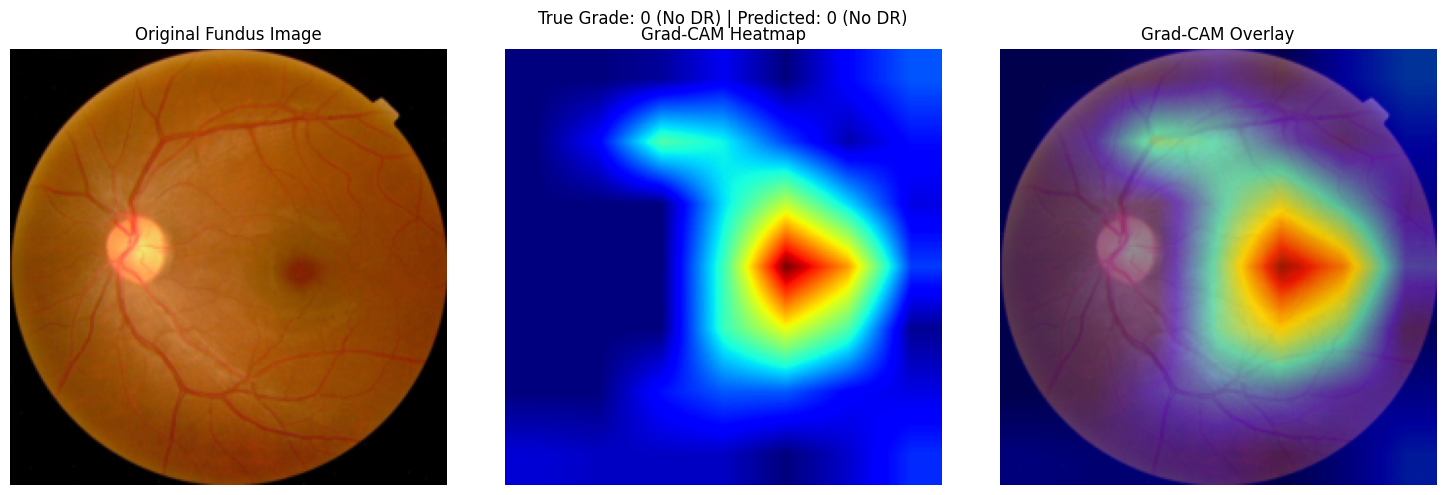

Saved to /kaggle/working/efficientnet_gradcam.png


In [29]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

# Use the existing trained model
model.eval()
device = next(model.parameters()).device

# EfficientNet final feature block
target_layers = [model.features[-1]]

# Get one validation batch
images, labels = next(iter(val_loader))
images = images.to(device)
labels = labels.to(device)

# Select one image
idx = 0
input_tensor = images[idx:idx+1]
true_grade = labels[idx].item()

# Predict
with torch.no_grad():
    logits = model(input_tensor)
    predicted_grade = logits.argmax(dim=1).item()

# Grad-CAM
with GradCAM(
    model=model,
    target_layers=target_layers
) as cam:
    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=[ClassifierOutputTarget(predicted_grade)]
    )[0]

# Convert normalized tensor back to an RGB image
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

rgb_img = input_tensor[0].detach().cpu().permute(1, 2, 0).numpy()
rgb_img = np.clip(rgb_img * std + mean, 0, 1)

# Overlay the Grad-CAM heatmap
visualization = show_cam_on_image(
    rgb_img.astype(np.float32),
    grayscale_cam,
    use_rgb=True
)

grade_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR"
]

# Display results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(rgb_img)
axes[0].set_title("Original Fundus Image")

axes[1].imshow(grayscale_cam, cmap="jet")
axes[1].set_title("Grad-CAM Heatmap")

axes[2].imshow(visualization)
axes[2].set_title("Grad-CAM Overlay")

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"True Grade: {true_grade} ({grade_names[true_grade]}) | "
    f"Predicted: {predicted_grade} ({grade_names[predicted_grade]})"
)
plt.tight_layout()
plt.savefig("/kaggle/working/efficientnet_gradcam.png",
            dpi=300, bbox_inches="tight")
plt.show()

print("Saved to /kaggle/working/efficientnet_gradcam.png")

In [43]:

import os

print("ConvNeXt model in memory:", "convnext_model" in globals())

if "convnext_model" in globals():
    print("ConvNeXt model is available!")
    print("Saving its weights now...")

    torch.save(
        convnext_model.state_dict(),
        "/kaggle/working/convnext-tiny.pth"
    )

    print("SUCCESS: ConvNeXt-Tiny saved!")
else:
    print("ConvNeXt model is not loaded in this session.")


ConvNeXt model in memory: True
ConvNeXt model is available!
Saving its weights now...
SUCCESS: ConvNeXt-Tiny saved!


In [44]:
import os

paths = [
    "/kaggle/working/efficientnet-B0.pth",
    "/kaggle/working/convnext-tiny.pth"
]

for path in paths:
    if os.path.exists(path):
        print("FOUND:", path)
        print("Size:", round(os.path.getsize(path) / (1024**2), 2), "MB")
    else:
        print("MISSING:", path)

FOUND: /kaggle/working/efficientnet-B0.pth
Size: 15.6 MB
FOUND: /kaggle/working/convnext-tiny.pth
Size: 106.2 MB


In [50]:
print("EfficientNet final feature layer:")
print(model.features[-1])

print("\nConvNeXt final classifier:")
print(convnext_model.classifier)

print("\nBoth models are ready for Grad-CAM.")

EfficientNet final feature layer:
Conv2dNormActivation(
  (0): Conv2d(320, 1280, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (1): BatchNorm2d(1280, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): SiLU(inplace=True)
)

ConvNeXt final classifier:
Sequential(
  (0): LayerNorm2d((768,), eps=1e-06, elementwise_affine=True)
  (1): Flatten(start_dim=1, end_dim=-1)
  (2): Sequential(
    (0): Dropout(p=0.4, inplace=False)
    (1): Linear(in_features=768, out_features=5, bias=True)
  )
)

Both models are ready for Grad-CAM.


In [52]:
print("=== ConvNeXt feature layers ===")

for name, module in convnext_model.named_modules():
    if isinstance(module, torch.nn.Conv2d):
        print(name, "->", module.__class__.__name__)

=== ConvNeXt feature layers ===
features.0.0 -> Conv2d
features.1.0.block.0 -> Conv2d
features.1.1.block.0 -> Conv2d
features.1.2.block.0 -> Conv2d
features.2.1 -> Conv2d
features.3.0.block.0 -> Conv2d
features.3.1.block.0 -> Conv2d
features.3.2.block.0 -> Conv2d
features.4.1 -> Conv2d
features.5.0.block.0 -> Conv2d
features.5.1.block.0 -> Conv2d
features.5.2.block.0 -> Conv2d
features.5.3.block.0 -> Conv2d
features.5.4.block.0 -> Conv2d
features.5.5.block.0 -> Conv2d
features.5.6.block.0 -> Conv2d
features.5.7.block.0 -> Conv2d
features.5.8.block.0 -> Conv2d
features.6.1 -> Conv2d
features.7.0.block.0 -> Conv2d
features.7.1.block.0 -> Conv2d
features.7.2.block.0 -> Conv2d


In [53]:
print("\n=== Top-level ConvNeXt modules ===")

for name, module in convnext_model.named_children():
    print(name, "->", module.__class__.__name__)


=== Top-level ConvNeXt modules ===
features -> Sequential
avgpool -> AdaptiveAvgPool2d
classifier -> Sequential


In [54]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

model.eval()
convnext_model.eval()

# Get one validation image
images, labels = next(iter(val_loader))
input_tensor = images[0:1].to(device)
true_grade = int(labels[0].item())

# Get the models' predictions and 50:50 ensemble prediction
with torch.no_grad():
    eff_probs = torch.softmax(model(input_tensor), dim=1)
    conv_probs = torch.softmax(convnext_model(input_tensor), dim=1)
    ensemble_probs = 0.5 * eff_probs + 0.5 * conv_probs

eff_pred = int(eff_probs.argmax(1).item())
conv_pred = int(conv_probs.argmax(1).item())
ensemble_pred = int(ensemble_probs.argmax(1).item())

# Correct target layers for your model implementations
eff_target_layer = model.features[-1]
conv_target_layer = convnext_model.features[-1]

with GradCAM(
    model=model,
    target_layers=[eff_target_layer]
) as cam_eff:
    eff_cam = cam_eff(
        input_tensor=input_tensor,
        targets=[ClassifierOutputTarget(eff_pred)]
    )[0]

with GradCAM(
    model=convnext_model,
    target_layers=[conv_target_layer]
) as cam_conv:
    conv_cam = cam_conv(
        input_tensor=input_tensor,
        targets=[ClassifierOutputTarget(conv_pred)]
    )[0]

print("True grade:", true_grade)
print("EfficientNet prediction:", eff_pred)
print("ConvNeXt prediction:", conv_pred)
print("50:50 ensemble prediction:", ensemble_pred)
print("EfficientNet heatmap shape:", eff_cam.shape)
print("ConvNeXt heatmap shape:", conv_cam.shape)

True grade: 0
EfficientNet prediction: 0
ConvNeXt prediction: 3
50:50 ensemble prediction: 1
EfficientNet heatmap shape: (224, 224)
ConvNeXt heatmap shape: (224, 224)


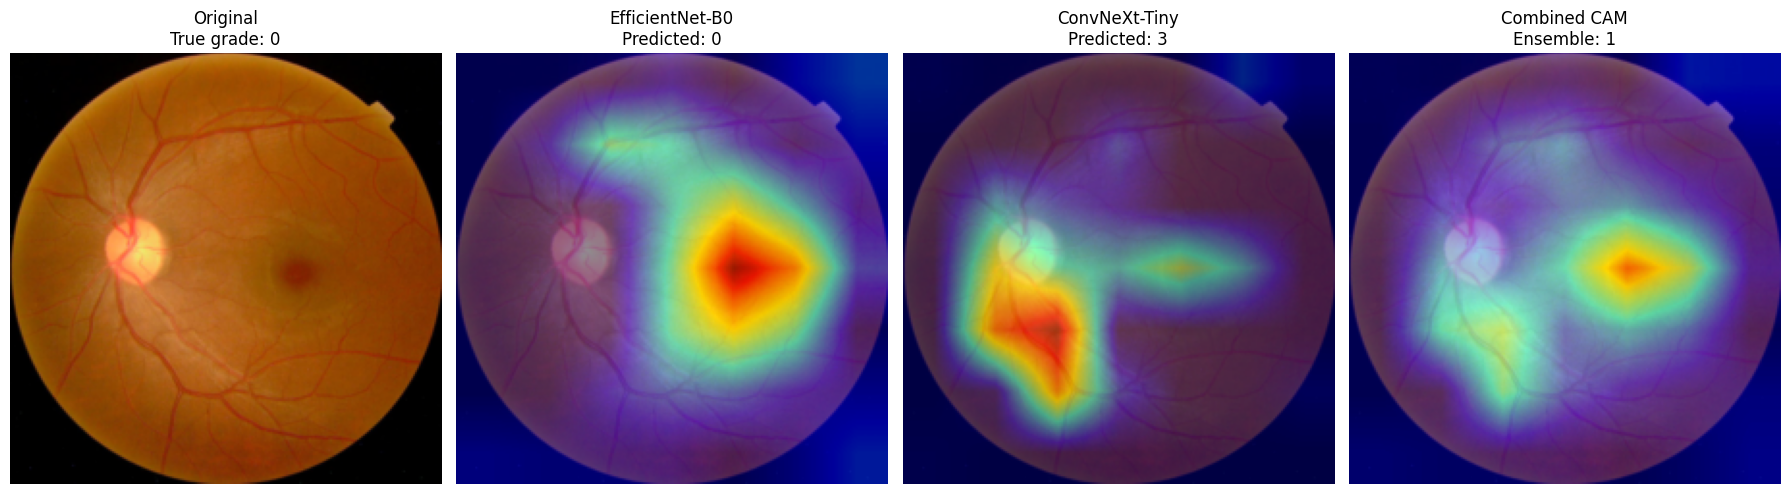

Saved: /kaggle/working/gradcam_comparison.png


In [55]:
from pytorch_grad_cam.utils.image import show_cam_on_image
import matplotlib.pyplot as plt
import numpy as np

# Convert the normalized image back to RGB
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

rgb = input_tensor[0].detach().cpu().permute(1, 2, 0).numpy()
rgb = np.clip(rgb * std + mean, 0, 1).astype(np.float32)

# Generate overlays
eff_overlay = show_cam_on_image(
    rgb, eff_cam, use_rgb=True
)

conv_overlay = show_cam_on_image(
    rgb, conv_cam, use_rgb=True
)

# Combined visualization of both heatmaps
combined_cam = (eff_cam + conv_cam) / 2
combined_overlay = show_cam_on_image(
    rgb, combined_cam.astype(np.float32), use_rgb=True
)

# Display all four panels
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(rgb)
axes[0].set_title(f"Original\nTrue grade: {true_grade}")

axes[1].imshow(eff_overlay)
axes[1].set_title(f"EfficientNet-B0\nPredicted: {eff_pred}")

axes[2].imshow(conv_overlay)
axes[2].set_title(f"ConvNeXt-Tiny\nPredicted: {conv_pred}")

axes[3].imshow(combined_overlay)
axes[3].set_title(f"Combined CAM\nEnsemble: {ensemble_pred}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.savefig(
    "/kaggle/working/gradcam_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Saved: /kaggle/working/gradcam_comparison.png")

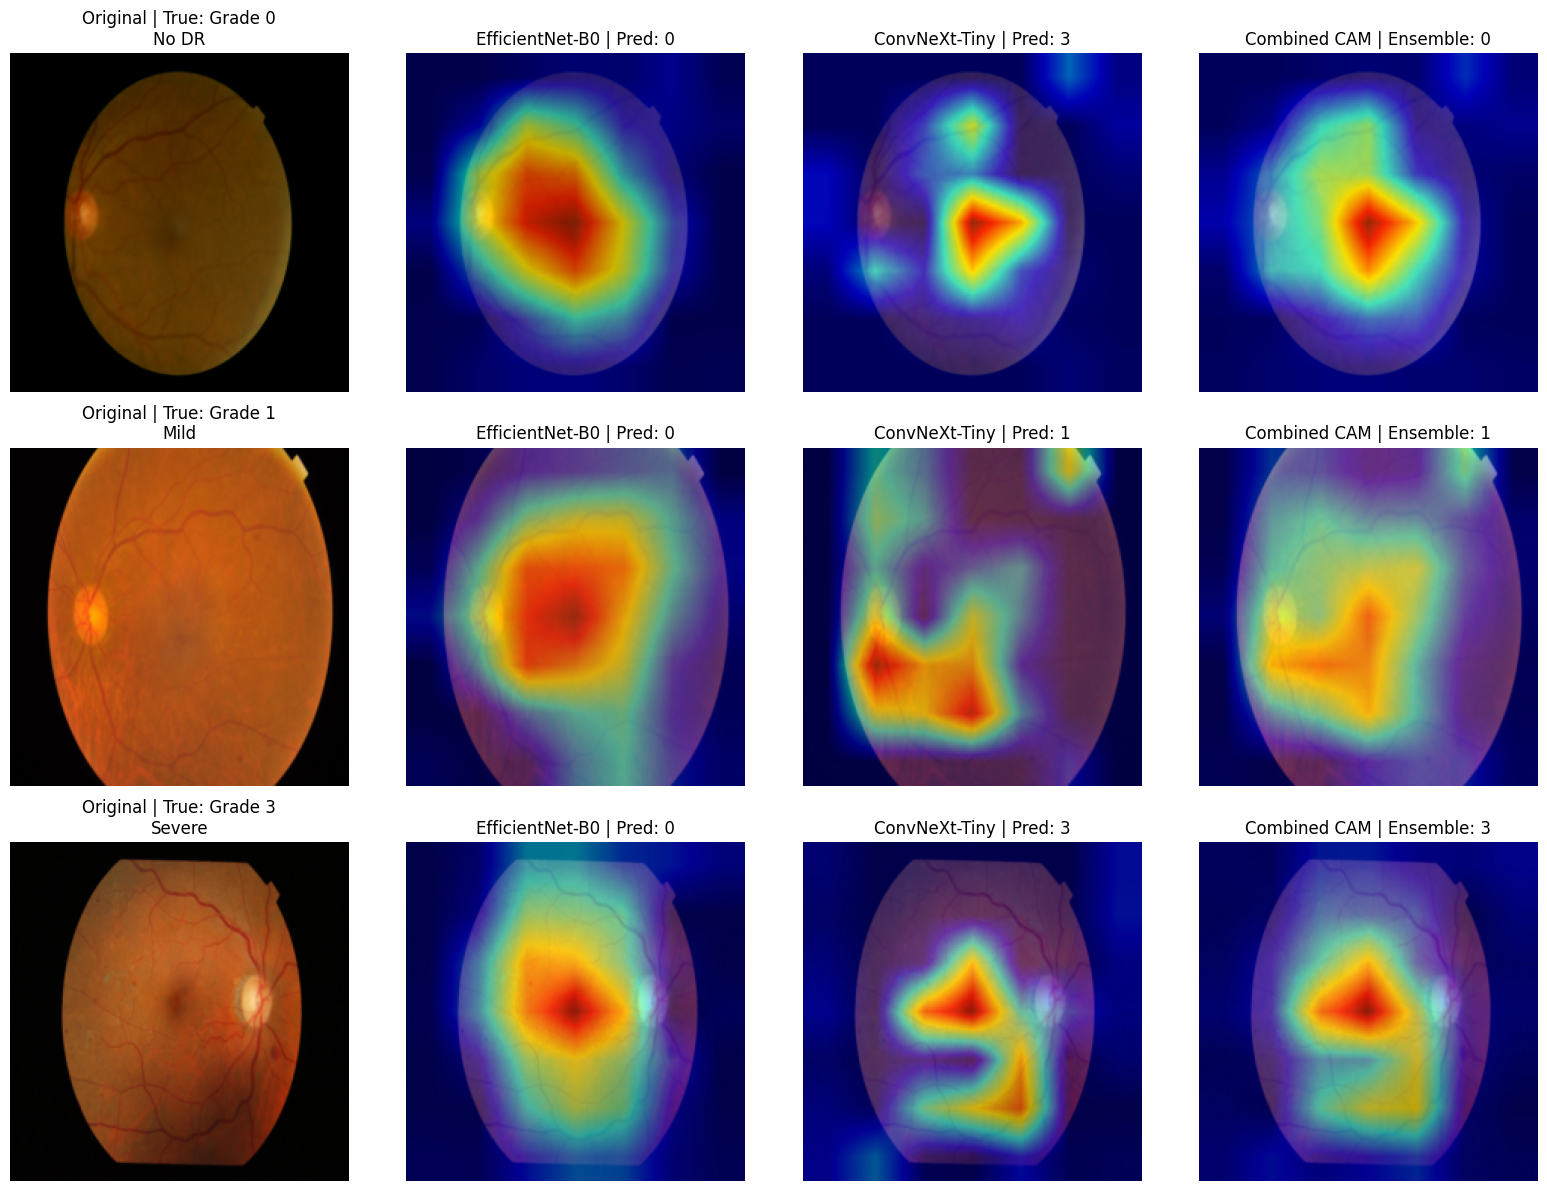

Saved to: /kaggle/working/gradcam_correct_grades_0_1_3.png


In [60]:

import numpy as np
import matplotlib.pyplot as plt
import torch

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

model.eval()
convnext_model.eval()

grade_names = {
    0: "No DR",
    1: "Mild",
    3: "Severe"
}

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

grades_to_show = [0, 1, 3]
fig, axes = plt.subplots(3, 4, figsize=(16, 12))

with GradCAM(
    model=model,
    target_layers=[model.features[-1]]
) as cam_eff, GradCAM(
    model=convnext_model,
    target_layers=[convnext_model.features[-1]]
) as cam_conv:

    for row, grade in enumerate(grades_to_show):
        sample = correct_examples_all[grade]

        if sample is None:
            for ax in axes[row]:
                ax.axis("off")
            continue

        x = sample["image"].unsqueeze(0).to(device)

        # Current model predictions
        with torch.no_grad():
            p_eff = torch.softmax(model(x), dim=1)
            p_conv = torch.softmax(convnext_model(x), dim=1)
            p_ens = 0.5 * p_eff + 0.5 * p_conv

        pred_eff = int(p_eff.argmax(1).item())
        pred_conv = int(p_conv.argmax(1).item())
        pred_ens = int(p_ens.argmax(1).item())

        # Explain each model's predicted class
        heat_eff = cam_eff(
            input_tensor=x,
            targets=[ClassifierOutputTarget(pred_eff)]
        )[0]

        heat_conv = cam_conv(
            input_tensor=x,
            targets=[ClassifierOutputTarget(pred_conv)]
        )[0]

        # Undo ImageNet normalization for display
        rgb = x[0].detach().cpu().permute(1, 2, 0).numpy()
        rgb = np.clip(rgb * std + mean, 0, 1).astype(np.float32)

        overlay_eff = show_cam_on_image(rgb, heat_eff, use_rgb=True)
        overlay_conv = show_cam_on_image(rgb, heat_conv, use_rgb=True)

        combined_heat = (heat_eff + heat_conv) / 2
        overlay_combined = show_cam_on_image(
            rgb, combined_heat.astype(np.float32), use_rgb=True
        )

        axes[row, 0].imshow(rgb)
        axes[row, 0].set_title(
            f"Original | True: Grade {grade}\n{grade_names[grade]}"
        )

        axes[row, 1].imshow(overlay_eff)
        axes[row, 1].set_title(f"EfficientNet-B0 | Pred: {pred_eff}")

        axes[row, 2].imshow(overlay_conv)
        axes[row, 2].set_title(f"ConvNeXt-Tiny | Pred: {pred_conv}")

        axes[row, 3].imshow(overlay_combined)
        axes[row, 3].set_title(f"Combined CAM | Ensemble: {pred_ens}")

        for ax in axes[row]:
            ax.axis("off")

plt.tight_layout()
output_path = "/kaggle/working/gradcam_correct_grades_0_1_3.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved to:", output_path)
